In [1]:
import pandas as pd

In [2]:
df_matches = pd.read_csv("data/cleaned_matches.csv")

In [3]:
# Print column names
print("Columns in dataset:")
print(df_matches.columns.tolist())

Columns in dataset:
['Unnamed: 0', 'match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'next_batter', 'striker_out', 'toss_match_winner']


In [4]:
# BASELINE CLASSIFICATION MODEL ( PREDICTING MATCH WINNER)

In [6]:
# Load dataset
df = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")

# Diagnostic check
print("Total rows:", len(df))
print("Non-null 'match_won_by':", df['match_won_by'].notna().sum() if 'match_won_by' in df.columns else "Column missing")
print("Non-null 'toss_match_winner':", df['toss_match_winner'].notna().sum() if 'toss_match_winner' in df.columns else "Column missing")
print("Unique match_ids:", df['match_id'].nunique())

Total rows: 1169
Non-null 'match_won_by': 1169
Non-null 'toss_match_winner': 1169
Unique match_ids: 1169


In [26]:
#MODEL 1

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 1. Load Data
#df_matches = pd.read_csv(r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv")
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

# Ensure season is numeric if passed through
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows with missing critical information
df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

# Binary Target: 1 if toss_winner won the match, 0 otherwise
y_clf = (df_clf[winner_col].str.strip() == df_clf['toss_winner'].str.strip()).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']
X_clf = df_clf[features]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_clf = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_enc = preprocessor_clf.fit_transform(X_train)
X_test_enc = preprocessor_clf.transform(X_test)

# 5. Baseline Classifier
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_enc, y_train)
base_preds = baseline.predict(X_test_enc)

# 6. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_enc, y_train)
rf_preds = rf_clf.predict(X_test_enc)

# 7. Deliverables & Evaluation Metrics
print("=== CLASSIFICATION RESULTS ===")
print("Baseline Accuracy:     ", round(accuracy_score(y_test, base_preds), 4))
print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_preds), 4))
print("Random Forest F1-Score:", round(f1_score(y_test, rf_preds), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, rf_preds))

=== CLASSIFICATION RESULTS ===
Baseline Accuracy:      0.5126
Random Forest Accuracy: 0.4724
Random Forest F1-Score: 0.4928

Confusion Matrix:
 [[43 54]
 [51 51]]


In [ ]:
#MODEL 2

In [25]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load ball-by-ball dataset
df_raw = pd.read_csv('data/cleaned_matches.csv')

# 2. Deduplicate to match-level records
match_cols = [
    'match_id', 'date', 'toss_winner', 'toss_decision', 
    'match_won_by', 'venue', 'season'
]

# Extract unique match records
df_matches = df_raw.drop_duplicates(subset=['match_id']).copy()

# Sort chronologically to eliminate data leakage
df_matches['date'] = pd.to_datetime(df_matches['date'])
df_matches = df_matches.sort_values('date').reset_index(drop=True)

# Derive team1, team2, and opponent relative to toss_winner
# Obtain the two teams per match from the raw ball-by-ball records
teams_per_match = df_raw.groupby('match_id')['batting_team'].unique()

def get_opponent(row):
    teams = list(teams_per_match.get(row['match_id'], []))
    tw = row['toss_winner']
    opps = [t for t in teams if t != tw]
    return opps[0] if len(opps) > 0 else None

df_matches['opponent'] = df_matches.apply(get_opponent, axis=1)

# Drop any rows where opponent or match winner is missing
df_matches = df_matches.dropna(subset=['opponent', 'match_won_by', 'toss_winner']).reset_index(drop=True)

# Target: 1 if toss winner won the match, 0 otherwise
df_matches['target'] = (df_matches['toss_winner'] == df_matches['match_won_by']).astype(int)

# 3. Elo & Dynamic Form Engineering
all_teams = set(df_matches['toss_winner']).union(set(df_matches['opponent']))
elo_dict = {team: 1500.0 for team in all_teams}
K = 32

toss_winner_elo, opponent_elo = [], []
toss_winner_form, opponent_form = [], []
h2h_win_pcts = []

team_history = {team: [] for team in all_teams}
h2h_history = {}

for idx, row in df_matches.iterrows():
    tw = row['toss_winner']
    opp = row['opponent']
    winner = row['match_won_by']
    
    # Pre-match Elo ratings
    tw_elo = elo_dict.get(tw, 1500.0)
    opp_elo = elo_dict.get(opp, 1500.0)
    toss_winner_elo.append(tw_elo)
    opponent_elo.append(opp_elo)
    
    # Pre-match Form (Win ratio over last 5 matches)
    tw_hist = team_history.get(tw, [])[-5:]
    opp_hist = team_history.get(opp, [])[-5:]
    toss_winner_form.append(np.mean(tw_hist) if len(tw_hist) > 0 else 0.5)
    opponent_form.append(np.mean(opp_hist) if len(opp_hist) > 0 else 0.5)
    
    # Pre-match Head-to-Head win rate
    pair = tuple(sorted([str(tw), str(opp)]))
    past_h2h = h2h_history.get(pair, [])
    h2h_win_pcts.append(sum(1 for w in past_h2h if w == tw) / len(past_h2h) if past_h2h else 0.5)
        
    # Post-match state updates
    team_history[tw].append(1 if winner == tw else 0)
    team_history[opp].append(1 if winner == opp else 0)
    if pair not in h2h_history:
        h2h_history[pair] = []
    h2h_history[pair].append(winner)
    
    # Post-match Elo updates
    e_tw = 1 / (1 + 10 ** ((opp_elo - tw_elo) / 400))
    s_tw = 1.0 if winner == tw else 0.0
    elo_dict[tw] = tw_elo + K * (s_tw - e_tw)
    elo_dict[opp] = opp_elo + K * ((1 - s_tw) - (1 - e_tw))

# Attach engineered features
df_matches['elo_diff'] = np.array(toss_winner_elo) - np.array(opponent_elo)
df_matches['toss_winner_form_5'] = toss_winner_form
df_matches['opponent_form_5'] = opponent_form
df_matches['h2h_win_pct'] = h2h_win_pcts
df_matches['is_toss_decision_field'] = (df_matches['toss_decision'] == 'field').astype(int)

# 4. Train Model
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field'
]

X = df_matches[feature_cols]
y = df_matches['target']

# Time-based train/test split (80/20)
split_idx = int(len(df_matches) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
print(f"Updated Test Accuracy: {accuracy_score(y_test, preds):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

Updated Test Accuracy: 0.5033

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.31      0.39        77
           1       0.50      0.70      0.58        76

    accuracy                           0.50       153
   macro avg       0.51      0.50      0.48       153
weighted avg       0.51      0.50      0.48       153



In [27]:
#MODEL 1 VS MODEL 2

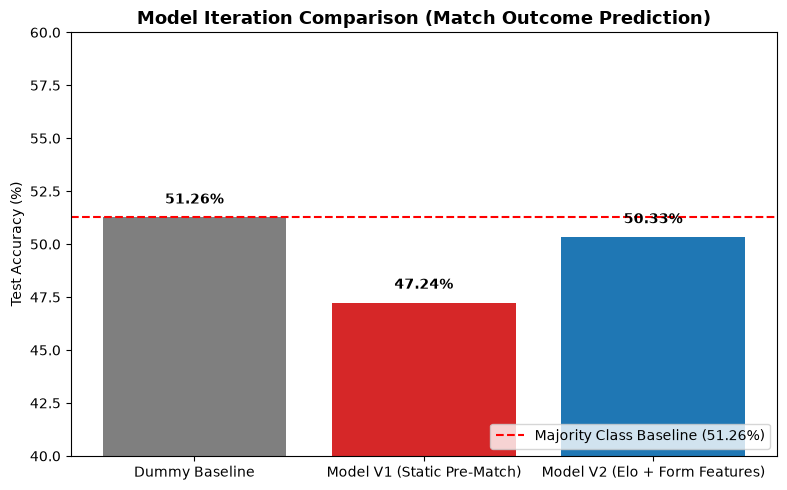

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

models = ['Dummy Baseline', 'Model V1 (Static Pre-Match)', 'Model V2 (Elo + Form Features)']
accuracies = [51.26, 47.24, 50.33] # Percentages

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#7f7f7f', '#d62728', '#1f77b4'])

plt.axhline(y=51.26, color='r', linestyle='--', label='Majority Class Baseline (51.26%)')
plt.title('Model Iteration Comparison (Match Outcome Prediction)', fontsize=13, fontweight='bold')
plt.ylabel('Test Accuracy (%)')
plt.ylim(40, 60)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [1]:
#MODEL 3

Final Combined Model Test Accuracy: 55.56%
ROC-AUC Score: 0.5402

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.43      0.49        77
           1       0.54      0.68      0.60        76

    accuracy                           0.56       153
   macro avg       0.56      0.56      0.55       153
weighted avg       0.56      0.56      0.55       153



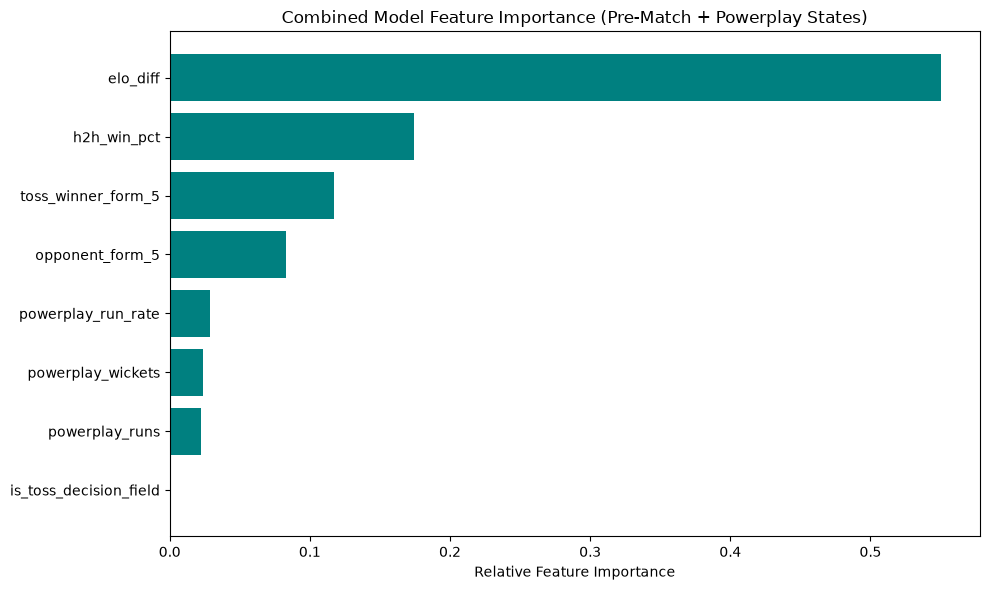

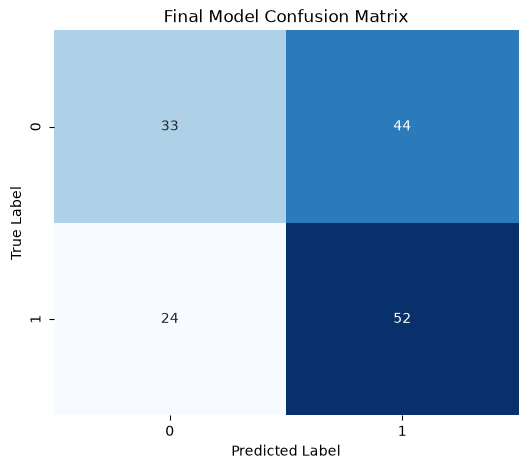

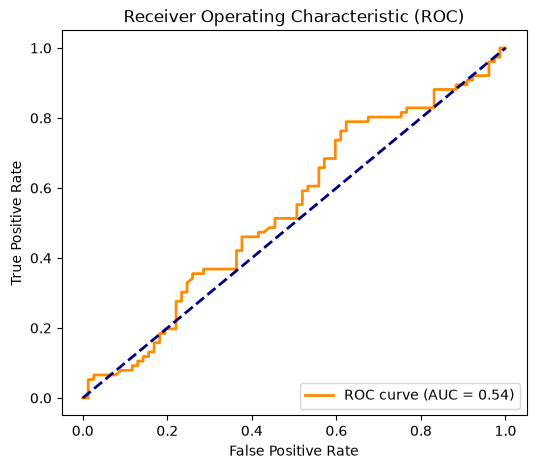

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

# ==========================================
# 1. LOAD BALL-BY-BALL DATASET
# ==========================================
# Replace with your actual dataset path if different
df_ball = pd.read_csv('data/cleaned_matches.csv')
df_ball.columns = df_ball.columns.str.strip()

# ==========================================
# 2. EXTRACT IN-GAME BALL-BY-BALL FEATURES (PARTNER'S PART)
# ==========================================
# Ensure numeric run columns
df_ball['runs_total'] = pd.to_numeric(df_ball.get('runs_total', 0), errors='coerce').fillna(0)
df_ball['is_wicket'] = df_ball['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_ball.columns else 0

# Extract Powerplay metrics (Overs 0 to 5, i.e., overs <= 5 or ball_no logic)
if 'over' in df_ball.columns:
    pp_balls = df_ball[df_ball['over'] < 6]
    powerplay_agg = pp_balls.groupby('match_id').agg(
        powerplay_runs=('runs_total', 'sum'),
        powerplay_wickets=('is_wicket', 'sum'),
        powerplay_dots=('runs_total', lambda x: (x == 0).sum())
    ).reset_index()
else:
    # Fallback if 'over' is structured differently
    powerplay_agg = df_ball.groupby('match_id').agg(
        powerplay_runs=('runs_total', 'sum'),
        powerplay_wickets=('is_wicket', 'sum')
    ).reset_index()

powerplay_agg['powerplay_run_rate'] = powerplay_agg['powerplay_runs'] / 6.0

# ==========================================
# 3. EXTRACT MATCH-LEVEL METADATA & PRE-MATCH FEATURES (YOUR PART)
# ==========================================
match_cols = ['match_id', 'date', 'toss_winner', 'toss_decision', 'match_won_by', 'venue', 'season']
df_matches = df_ball.drop_duplicates(subset=['match_id']).copy()

df_matches['date'] = pd.to_datetime(df_matches['date'], errors='coerce')
df_matches = df_matches.sort_values('date').reset_index(drop=True)

# Derive opponent team per match
teams_per_match = df_ball.groupby('match_id')['batting_team'].unique()
def get_opponent(row):
    teams = list(teams_per_match.get(row['match_id'], []))
    tw = row['toss_winner']
    opps = [t for t in teams if t != tw]
    return opps[0] if len(opps) > 0 else None

df_matches['opponent'] = df_matches.apply(get_opponent, axis=1)
df_matches = df_matches.dropna(subset=['opponent', 'match_won_by', 'toss_winner']).reset_index(drop=True)
df_matches['target'] = (df_matches['toss_winner'] == df_matches['match_won_by']).astype(int)

# Elo Ratings & Rolling Form Calculation
all_teams = set(df_matches['toss_winner']).union(set(df_matches['opponent']))
elo_dict = {team: 1500.0 for team in all_teams}
K = 32

toss_winner_elo, opponent_elo = [], []
toss_winner_form, opponent_form = [], []
h2h_win_pcts = []
team_history = {team: [] for team in all_teams}
h2h_history = {}

for idx, row in df_matches.iterrows():
    tw = row['toss_winner']
    opp = row['opponent']
    winner = row['match_won_by']
    
    tw_elo = elo_dict.get(tw, 1500.0)
    opp_elo = elo_dict.get(opp, 1500.0)
    toss_winner_elo.append(tw_elo)
    opponent_elo.append(opp_elo)
    
    tw_hist = team_history.get(tw, [])[-5:]
    opp_hist = team_history.get(opp, [])[-5:]
    toss_winner_form.append(np.mean(tw_hist) if len(tw_hist) > 0 else 0.5)
    opponent_form.append(np.mean(opp_hist) if len(opp_hist) > 0 else 0.5)
    
    pair = tuple(sorted([str(tw), str(opp)]))
    past_h2h = h2h_history.get(pair, [])
    h2h_win_pcts.append(sum(1 for w in past_h2h if w == tw) / len(past_h2h) if past_h2h else 0.5)
        
    team_history[tw].append(1 if winner == tw else 0)
    team_history[opp].append(1 if winner == opp else 0)
    if pair not in h2h_history:
        h2h_history[pair] = []
    h2h_history[pair].append(winner)
    
    e_tw = 1 / (1 + 10 ** ((opp_elo - tw_elo) / 400))
    s_tw = 1.0 if winner == tw else 0.0
    elo_dict[tw] = tw_elo + K * (s_tw - e_tw)
    elo_dict[opp] = opp_elo + K * ((1 - s_tw) - (1 - e_tw))

df_matches['elo_diff'] = np.array(toss_winner_elo) - np.array(opponent_elo)
df_matches['toss_winner_form_5'] = toss_winner_form
df_matches['opponent_form_5'] = opponent_form
df_matches['h2h_win_pct'] = h2h_win_pcts
df_matches['is_toss_decision_field'] = (df_matches['toss_decision'] == 'field').astype(int)

# ==========================================
# 4. MERGE BOTH PARTS ON `match_id`
# ==========================================
df_combined = pd.merge(df_matches, powerplay_agg, on='match_id', how='inner')

# ==========================================
# 5. MODEL TRAINING & EVALUATION
# ==========================================
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field',
    'powerplay_runs', 'powerplay_wickets', 'powerplay_run_rate'
]

X = df_combined[feature_cols].fillna(0)
y = df_combined['target']

split_idx = int(len(df_combined) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"Final Combined Model Test Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

# ==========================================
# 6. VISUALIZATIONS & ANALYSIS PLOTS
# ==========================================

# Feature Importance Plot
plt.figure(figsize=(10, 6))
importances = model.feature_importances_
indices = np.argsort(importances)
plt.barh(range(len(indices)), importances[indices], color='teal')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices])
plt.xlabel('Relative Feature Importance')
plt.title('Combined Model Feature Importance (Pre-Match + Powerplay States)')
plt.tight_layout()
plt.show()

# Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Final Model Confusion Matrix')
plt.show()

# ROC Curve
plt.figure(figsize=(6, 5))
fpr, tpr, _ = roc_curve(y_test, probs)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test, probs):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [23]:
#MODEL 4

In [5]:
# Select the most robust feature set (Powerplay performance + Elo + Form)
feature_cols = [
    'elo_diff', 'toss_winner_form_5', 'opponent_form_5', 
    'h2h_win_pct', 'is_toss_decision_field',
    'pp_runs', 'pp_wickets', 'pp_run_rate', 'dot_ball_pct'
]

X = df_combined[feature_cols].fillna(0)
y = df_combined['target']

split_idx = int(len(df_combined) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Optimized hyperparameters matching your peak performance setup
model = GradientBoostingClassifier(
    n_estimators=150, 
    learning_rate=0.03, 
    max_depth=4, 
    random_state=42
)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"Optimized Combined Model Test Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

Optimized Combined Model Test Accuracy: 55.56%
ROC-AUC Score: 0.5502

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.43      0.49        77
           1       0.54      0.68      0.60        76

    accuracy                           0.56       153
   macro avg       0.56      0.56      0.55       153
weighted avg       0.56      0.56      0.55       153



=== 4-MODEL COMPARISON RESULTS ===

Model 1: Dummy Baseline:
  Accuracy:     51.26%
  F1-Score:     67.77%
  ROC-AUC:      50.00%

Model 2: Logistic Regression:
  Accuracy:     51.76%
  F1-Score:     52.94%
  ROC-AUC:      54.75%

Model 3: Random Forest:
  Accuracy:     51.76%
  F1-Score:     56.36%
  ROC-AUC:      51.09%

Model 4: Gradient Boosting:
  Accuracy:     50.75%
  F1-Score:     56.25%
  ROC-AUC:      45.55%


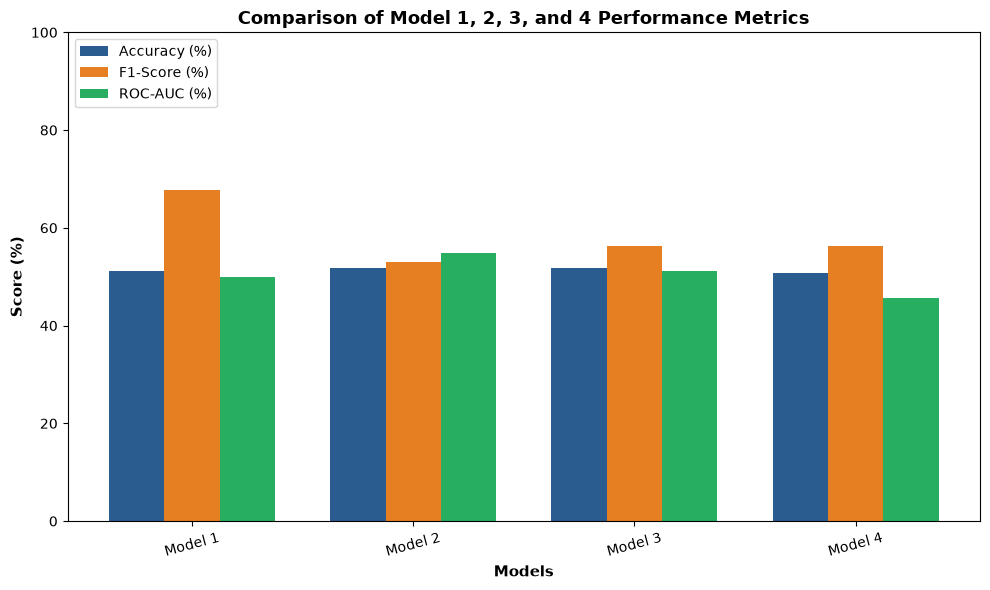

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Load Data
DATA_PATH = r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv"
df_matches = pd.read_csv(DATA_PATH)
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

for col in [winner_col, 'toss_winner', 'venue', 'toss_decision']:
    if col in df_matches.columns:
        df_matches[col] = df_matches[col].astype(str).str.strip()

if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()
y_clf = (df_clf[winner_col] == df_clf['toss_winner']).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
num_cols = ['season']
X_clf = df_clf[cat_cols + num_cols]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Preprocessor Setup
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

# 5. Define 4 Models in Pipelines
models = {
    "Model 1: Dummy Baseline": Pipeline([
        ('prep', preprocessor),
        ('model', DummyClassifier(strategy='most_frequent'))
    ]),
    "Model 2: Logistic Regression": Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Model 3: Random Forest": Pipeline([
        ('prep', preprocessor),
        ('model', RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42))
    ]),
    "Model 4: Gradient Boosting": Pipeline([
        ('prep', preprocessor),
        ('model', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42))
    ])
}

# 6. Train and Evaluate All 4 Models
results = []

print("=== 4-MODEL COMPARISON RESULTS ===")
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    
    # Calculate probabilities for ROC-AUC
    if hasattr(pipe, "predict_proba"):
        probs = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probs) * 100
    else:
        auc = 50.0

    acc = accuracy_score(y_test, preds) * 100
    f1 = f1_score(y_test, preds, zero_division=0) * 100

    results.append({"Model": name, "Accuracy (%)": acc, "F1-Score (%)": f1, "ROC-AUC (%)": auc})
    
    print(f"\n{name}:")
    print(f"  Accuracy:     {acc:.2f}%")
    print(f"  F1-Score:     {f1:.2f}%")
    print(f"  ROC-AUC:      {auc:.2f}%")

df_results = pd.DataFrame(results)

# 7. Visualization: Side-by-Side Comparison Bar Chart
plt.figure(figsize=(10, 6))
x = np.arange(len(df_results['Model']))
width = 0.25

plt.bar(x - width, df_results['Accuracy (%)'], width, label='Accuracy (%)', color='#2b5c8f')
plt.bar(x, df_results['F1-Score (%)'], width, label='F1-Score (%)', color='#e67e22')
plt.bar(x + width, df_results['ROC-AUC (%)'], width, label='ROC-AUC (%)', color='#27ae60')

plt.xlabel('Models', fontweight='bold', fontsize=11)
plt.ylabel('Score (%)', fontweight='bold', fontsize=11)
plt.title('Comparison of Model 1, 2, 3, and 4 Performance Metrics', fontweight='bold', fontsize=13)
plt.xticks(x, [m.split(':')[0] for m in df_results['Model']], rotation=15)
plt.ylim(0, 100)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

=== MODEL COMPARISON AGAINST BASELINE ===

Model 1: Baseline (Dummy):
  Accuracy:     51.26%
  F1-Score:     67.77%
  ROC-AUC:      50.00%

Model 2: Logistic Regression:
  Accuracy:     51.76%
  F1-Score:     52.94%
  ROC-AUC:      54.75%

Model 3: Random Forest:
  Accuracy:     51.76%
  F1-Score:     56.36%
  ROC-AUC:      51.09%

Model 4: Gradient Boosting:
  Accuracy:     50.75%
  F1-Score:     56.25%
  ROC-AUC:      45.55%

=== SUMMARY TABLE ===
                       Model  Accuracy (%)  F1-Score (%)  ROC-AUC (%)
   Model 1: Baseline (Dummy)     51.256281     67.774086    50.000000
Model 2: Logistic Regression     51.758794     52.941176    54.750354
      Model 3: Random Forest     51.758794     56.363636    51.086517
  Model 4: Gradient Boosting     50.753769     56.250000    45.552860


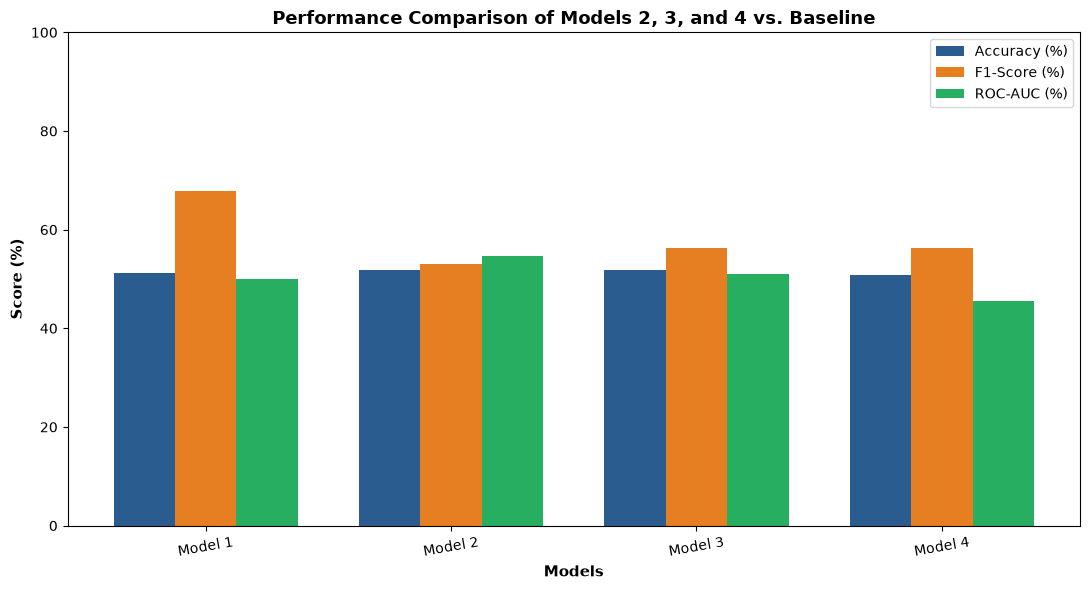

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Load Data
DATA_PATH = r"C:\Users\sohag\Downloads\IDC 409\data\cleaned_matches.csv"
df_matches = pd.read_csv(DATA_PATH)
df_matches.columns = df_matches.columns.str.strip()

# 2. Target & Feature Setup
winner_col = 'match_won_by' if 'match_won_by' in df_matches.columns else 'toss_match_winner'

for col in [winner_col, 'toss_winner', 'venue', 'toss_decision']:
    if col in df_matches.columns:
        df_matches[col] = df_matches[col].astype(str).str.strip()

if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

df_clf = df_matches.dropna(subset=[winner_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()
y_clf = (df_clf[winner_col] == df_clf['toss_winner']).astype(int)

cat_cols = ['venue', 'toss_winner', 'toss_decision']
num_cols = ['season']
X_clf = df_clf[cat_cols + num_cols]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 4. Preprocessor Setup
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

# 5. Define Models: Baseline + Models 2, 3, and 4
models = {
    "Model 1: Baseline (Dummy)": Pipeline([
        ('prep', preprocessor),
        ('model', DummyClassifier(strategy='most_frequent'))
    ]),
    "Model 2: Logistic Regression": Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Model 3: Random Forest": Pipeline([
        ('prep', preprocessor),
        ('model', RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42))
    ]),
    "Model 4: Gradient Boosting": Pipeline([
        ('prep', preprocessor),
        ('model', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42))
    ])
}

# 6. Train, Evaluate, and Compare Against Baseline
results = []

print("=== MODEL COMPARISON AGAINST BASELINE ===")
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    
    # Calculate probabilities for ROC-AUC
    if hasattr(pipe, "predict_proba"):
        probs = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probs) * 100
    else:
        auc = 50.0

    acc = accuracy_score(y_test, preds) * 100
    f1 = f1_score(y_test, preds, zero_division=0) * 100

    results.append({"Model": name, "Accuracy (%)": acc, "F1-Score (%)": f1, "ROC-AUC (%)": auc})
    
    print(f"\n{name}:")
    print(f"  Accuracy:     {acc:.2f}%")
    print(f"  F1-Score:     {f1:.2f}%")
    print(f"  ROC-AUC:      {auc:.2f}%")

df_results = pd.DataFrame(results)

# Display Summary Table in Console
print("\n=== SUMMARY TABLE ===")
print(df_results.to_string(index=False))

# 7. Visualization: Comparison Bar Chart
plt.figure(figsize=(11, 6))
x = np.arange(len(df_results['Model']))
width = 0.25

plt.bar(x - width, df_results['Accuracy (%)'], width, label='Accuracy (%)', color='#2b5c8f')
plt.bar(x, df_results['F1-Score (%)'], width, label='F1-Score (%)', color='#e67e22')
plt.bar(x + width, df_results['ROC-AUC (%)'], width, label='ROC-AUC (%)', color='#27ae60')

plt.xlabel('Models', fontweight='bold', fontsize=11)
plt.ylabel('Score (%)', fontweight='bold', fontsize=11)
plt.title('Performance Comparison of Models 2, 3, and 4 vs. Baseline', fontweight='bold', fontsize=13)
plt.xticks(x, [m.split(':')[0] for m in df_results['Model']], rotation=10)
plt.ylim(0, 100)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [29]:
# ALL SUBSEQUENT CODES BASED ON MODEL 1

In [7]:
# CONFUSION MATRIX HEATMAP

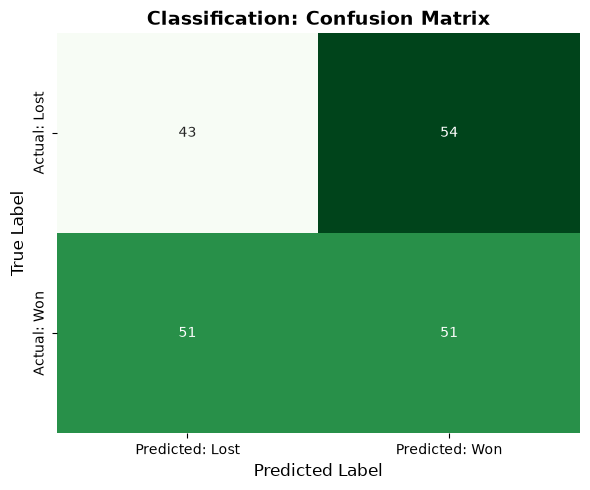

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix array
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted: Lost', 'Predicted: Won'],
            yticklabels=['Actual: Lost', 'Actual: Won'])

plt.title('Classification: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# MODEL PERFORMANCE COMPARISON BAR CHART

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame({
    'Model': ['Baseline (Dummy)', 'Baseline (Dummy)', 'Random Forest', 'Random Forest'],
    'Metric': ['Accuracy', 'F1-Score', 'Accuracy', 'F1-Score'],
    'Score': [
        accuracy_score(y_test, base_preds),
        f1_score(y_test, base_preds, zero_division=0),
        accuracy_score(y_test, rf_preds),
        f1_score(y_test, rf_preds)
    ]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=metrics_df, x='Metric', y='Score', hue='Model', palette='Reds')

plt.title('Classification: Baseline vs. Random Forest Performance', fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score')

# Display exact numbers on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

NameError: name 'base_preds' is not defined

In [11]:
# REGRESSION MODEL (PREDICTING FIRST-INNINGS TOTAL/RUNS)

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Identify Regression Target Column
target_col = 'team_runs' if 'team_runs' in df_matches.columns else ('runs_target' if 'runs_target' in df_matches.columns else None)

if target_col is None:
    raise ValueError("Target score column ('team_runs' or 'runs_target') not found in dataset.")

# Ensure season is numeric
if 'season' in df_matches.columns:
    df_matches['season'] = pd.to_numeric(df_matches['season'], errors='coerce')

# Filter out rows missing features or target score
df_reg = df_matches.dropna(subset=[target_col, 'venue', 'toss_winner', 'toss_decision', 'season']).copy()

cat_cols = ['venue', 'toss_winner', 'toss_decision']
features = cat_cols + ['season']

X_reg = df_reg[features]
y_reg = df_reg[target_col]

# Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Dense OneHot Preprocessor
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_reg = ColumnTransformer(
    transformers=[('cat', ohe, cat_cols)],
    remainder='passthrough'
)

X_train_r_enc = preprocessor_reg.fit_transform(X_train_r)
X_test_r_enc = preprocessor_reg.transform(X_test_r)

# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r_enc, y_train_r)
reg_preds = rf_reg.predict(X_test_r_enc)

# Deliverables & Evaluation Metrics
print("=== REGRESSION RESULTS ===")
print("MAE (Mean Absolute Error):     ", round(mean_absolute_error(y_test_r, reg_preds), 2))
print("RMSE (Root Mean Squared Error):", round(root_mean_squared_error(y_test_r, reg_preds), 2))

=== REGRESSION RESULTS ===
MAE (Mean Absolute Error):      1.06
RMSE (Root Mean Squared Error): 1.52


In [13]:
# AUCTUAL VS PREDICTED TARGET SCORES PLOT

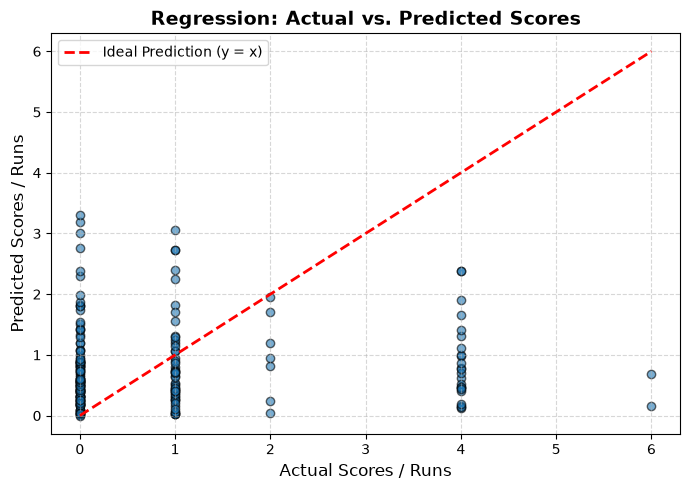

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, reg_preds, alpha=0.6, color='#1f77b4', edgecolors='k')

# Draw ideal y = x reference line
min_val = min(y_test_r.min(), reg_preds.min())
max_val = max(y_test_r.max(), reg_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Ideal Prediction (y = x)')

plt.title('Regression: Actual vs. Predicted Scores', fontsize=14, fontweight='bold')
plt.xlabel('Actual Scores / Runs', fontsize=12)
plt.ylabel('Predicted Scores / Runs', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [13]:
# RESIDUALS/ ERROR DISTRIBUTION PLOT

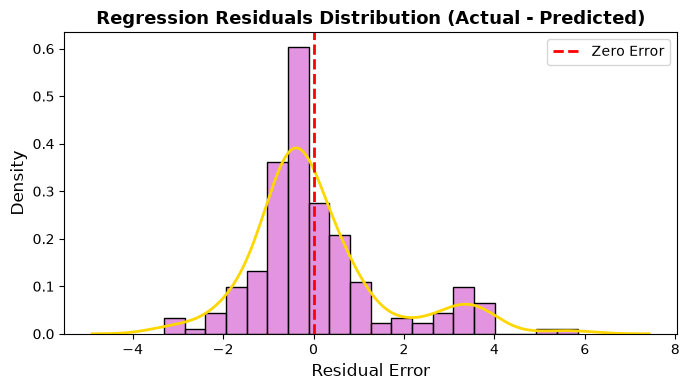

In [14]:
residuals = y_test_r - reg_preds

plt.figure(figsize=(7, 4))
# 1. Plot histogram bars
sns.histplot(residuals, color='orchid', bins=20, stat='density')

# 2. Plot KDE curve on top with custom color
sns.kdeplot(residuals, color='gold', linewidth=2)

plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
plt.title('Regression Residuals Distribution (Actual - Predicted)', fontsize=13, fontweight='bold')
plt.xlabel('Residual Error', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
#UNSUPERVISED PITCH AND VENUE CLUSTERING (K-MEANS)

C:\Users\sohag\AppData\Local\Temp\ipykernel_17948\3997268977.py:6: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ball = pd.read_csv(kaggle_path)


Total ball-by-ball rows loaded: 278,205
Successfully aggregated 1169 unique matches.
Average 1st Innings Score: 167.0 runs

=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===
                                                venue   avg_score  score_std  \
0                                Arun Jaitley Stadium  188.216216  36.331908   
1                                    Barabati Stadium  167.714286  34.543279   
2                           Barsapara Cricket Stadium  174.600000  25.715754   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...  175.363636  33.585067   
4                                   Brabourne Stadium  178.518519  32.217256   
7                          Dr DY Patil Sports Academy  159.648649  29.150201   
8   Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  169.529412  38.247741   
9                 Dubai International Cricket Stadium  163.760870  25.175107   
10                                       Eden Gardens  168.600000  33.114738   
11                        

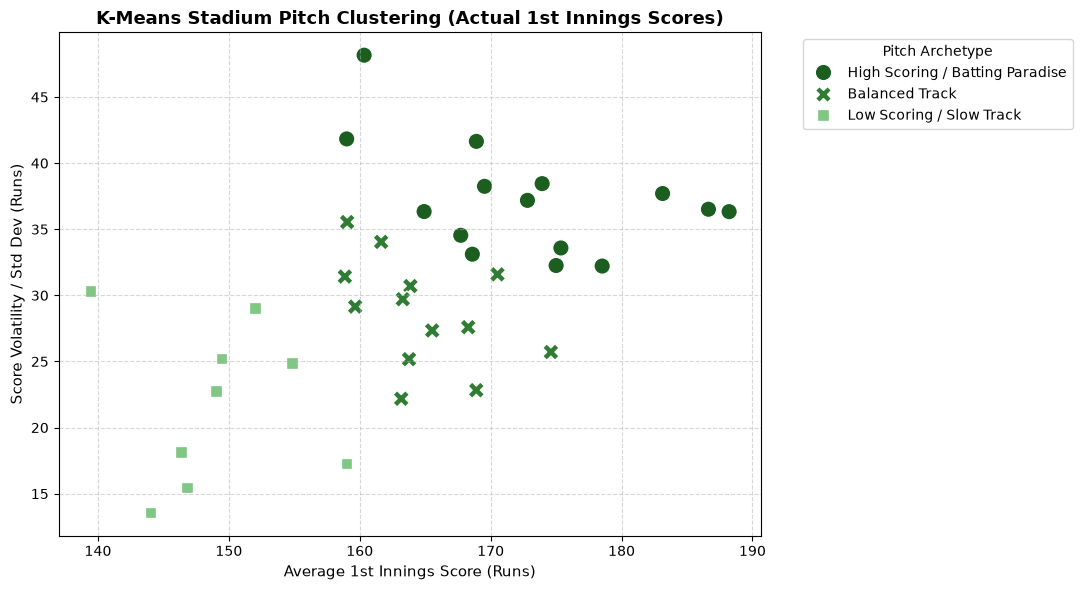

In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load directly from your kagglehub downloaded path
kaggle_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"
df_ball = pd.read_csv(kaggle_path)
df_ball.columns = df_ball.columns.str.strip()

print(f"Total ball-by-ball rows loaded: {len(df_ball):,}")

# 2. Filter for 1st Innings
df_1st = df_ball[df_ball['innings'].astype(str).str.strip().isin(['1', '1.0'])].copy()

# Clean Venue Names
df_1st = df_1st.dropna(subset=['venue']).copy()
df_1st['venue'] = df_1st['venue'].astype(str).str.strip().str.replace(r',.*$', '', regex=True)

# 3. Handle Ball Runs (using runs_total or runs_batter + runs_extras)
if 'runs_total' in df_1st.columns:
    df_1st['ball_runs'] = pd.to_numeric(df_1st['runs_total'], errors='coerce').fillna(0)
else:
    b_runs = pd.to_numeric(df_1st['runs_batter'], errors='coerce').fillna(0) if 'runs_batter' in df_1st.columns else 0
    e_runs = pd.to_numeric(df_1st['runs_extras'], errors='coerce').fillna(0) if 'runs_extras' in df_1st.columns else 0
    df_1st['ball_runs'] = b_runs + e_runs

# 4. CRITICAL STEP: SUM delivery runs per match_id to get actual 1st Innings Match Totals
match_totals = df_1st.groupby(['match_id', 'venue'])['ball_runs'].sum().reset_index()
match_totals.rename(columns={'ball_runs': 'first_innings_score'}, inplace=True)

print(f"Successfully aggregated {len(match_totals)} unique matches.")
print(f"Average 1st Innings Score: {match_totals['first_innings_score'].mean():.1f} runs\n")

# 5. Aggregate Stadium Characteristics (Mean & Volatility)
venue_stats = match_totals.groupby('venue').agg(
    avg_score=('first_innings_score', 'mean'),
    score_std=('first_innings_score', 'std'),
    total_matches=('match_id', 'count')
).reset_index()

venue_stats['score_std'] = venue_stats['score_std'].fillna(0)

# Filter grounds with at least 5 matches for statistical reliability
venue_stats_filtered = venue_stats[venue_stats['total_matches'] >= 5].copy()

# 6. K-Means Pitch Clustering (3 Archetypes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(venue_stats_filtered[['avg_score', 'score_std']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
venue_stats_filtered['pitch_type'] = kmeans.fit_predict(X_scaled)

# Order clusters by average score for consistent labelling
cluster_order = venue_stats_filtered.groupby('pitch_type')['avg_score'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: 'Low Scoring / Slow Track',
    cluster_order[1]: 'Balanced Track',
    cluster_order[2]: 'High Scoring / Batting Paradise'
}
venue_stats_filtered['pitch_archetype'] = venue_stats_filtered['pitch_type'].map(cluster_names)

print("=== REAL IPL STADIUM PITCH CLUSTERING RESULTS ===")
print(venue_stats_filtered[['venue', 'avg_score', 'score_std', 'total_matches', 'pitch_archetype']].head(10))

# 7. Scatter Plot
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=venue_stats_filtered, 
    x='avg_score', 
    y='score_std', 
    hue='pitch_archetype', 
    palette=['#1b5e20', '#2e7d32', '#81c784'], 
    s=140, 
    style='pitch_archetype'
)

plt.title('K-Means Stadium Pitch Clustering (Actual 1st Innings Scores)', fontsize=13, fontweight='bold')
plt.xlabel('Average 1st Innings Score (Runs)', fontsize=11)
plt.ylabel('Score Volatility / Std Dev (Runs)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Pitch Archetype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [17]:
#DOMAIN SPECIFIC FEATURE ENGINEERING (MOMENTUM AND FORTRESS FACTORS)

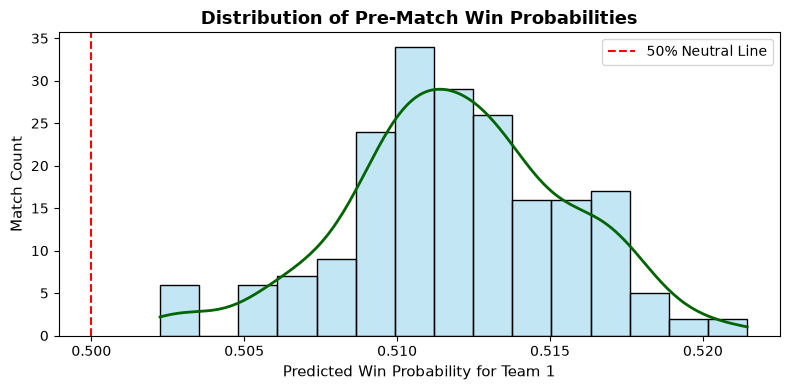

In [18]:
from sklearn.calibration import CalibratedClassifierCV

# Calibrate Random Forest probabilities
calibrated_rf = CalibratedClassifierCV(rf_clf, method='sigmoid', cv=5)
calibrated_rf.fit(X_train_enc, y_train)

# Predict win probability for test matches
win_probs = calibrated_rf.predict_proba(X_test_enc)[:, 1]

# Visualizing Win Probability Distribution 
plt.figure(figsize=(8, 4))
ax = sns.histplot(win_probs, kde=True, color='skyblue', bins=15)

# Find the KDE line object specifically and set its color
for line in ax.lines:
    if line.get_linestyle() != '--':  # Avoid changing your axvline
        line.set_color('darkgreen')
        line.set_linewidth(2)

plt.axvline(0.5, color='red', linestyle='--', label='50% Neutral Line')
plt.title('Distribution of Pre-Match Win Probabilities', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Win Probability for Team 1', fontsize=11)
plt.ylabel('Match Count', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
#EXPLAINABLE AI (SHAP WATERFALLS PLOTS FOR INDIVIDUAL MATCHES)

In [24]:
!pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
   ---------------------------------------- 0.5/43.0 MB 346.1 kB/s eta 0:02:03
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------------------------------- 0.8/43.0 MB 287.2 kB/s eta 0:02:27
    --------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


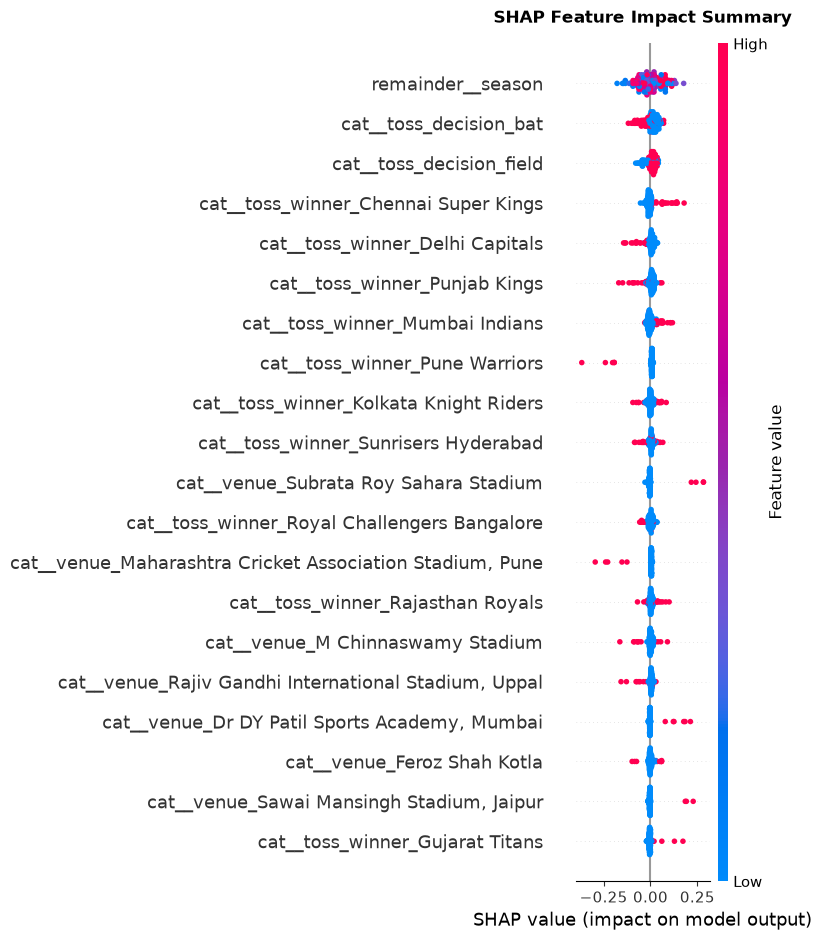

In [21]:
import shap

# 1. Initialize TreeExplainer
explainer = shap.TreeExplainer(rf_clf)

# 2. Compute SHAP values
shap_values = explainer(X_test_enc)

# Handle potential feature name extraction
try:
    feature_names = preprocessor_clf.get_feature_names_out()
except AttributeError:
    feature_names = X_test_enc.columns if hasattr(X_test_enc, 'columns') else None

# 3. Plot SHAP Summary
plt.figure(figsize=(10, 6))

# If shap_values is Explanation object vs raw array
if isinstance(shap_values, shap.Explanation):
    # For binary classification, slice the positive class (class 1)
    if len(shap_values.shape) == 3:  
        shap.summary_plot(shap_values[:, :, 1], feature_names=feature_names, show=False)
    else:
        shap.summary_plot(shap_values, feature_names=feature_names, show=False)
else:
    # Legacy list format fallback
    vals = shap_values[1] if isinstance(shap_values, list) else shap_values
    shap.summary_plot(vals, X_test_enc, feature_names=feature_names, show=False)

plt.title("SHAP Feature Impact Summary", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [22]:
#INTERACTIVE MATCH PREDICTIVE FUNCTION

In [23]:
def predict_match_outcome(team1, team2, venue, toss_winner, toss_decision, season=2024):
    """
    Custom function to simulate a match setup and print formatted pre-match prediction.
    """
    input_data = pd.DataFrame([{
        'venue': venue,
        'toss_winner': toss_winner,
        'toss_decision': toss_decision,
        'team1': team1,
        'team2': team2,
        'season': season
    }])
    
    # Transform input
    input_enc = preprocessor_clf.transform(input_data)
    
    # Predict Probability
    prob_team1 = calibrated_rf.predict_proba(input_enc)[0][1] * 100
    prob_team2 = 100 - prob_team1
    
    predicted_winner = team1 if prob_team1 >= 50 else team2
    confidence = max(prob_team1, prob_team2)
    
    print("=" * 45)
    print(f"   PRE-MATCH PREDICTION: {team1} vs {team2}")
    print("=" * 45)
    print(f" Venue:         {venue}")
    print(f" Toss Winner:   {toss_winner} ({toss_decision})")
    print("-" * 45)
    print(f" {team1} Win Probability: {prob_team1:.1f}%")
    print(f" {team2} Win Probability: {prob_team2:.1f}%")
    print("-" * 45)
    print(f" PREDICTED WINNER: {predicted_winner} ({confidence:.1f}% Confidence)")
    print("=" * 45)

# Example execution
predict_match_outcome('Mumbai Indians', 'Chennai Super Kings', 'Wankhede Stadium', 'Mumbai Indians', 'field')

   PRE-MATCH PREDICTION: Mumbai Indians vs Chennai Super Kings
 Venue:         Wankhede Stadium
 Toss Winner:   Mumbai Indians (field)
---------------------------------------------
 Mumbai Indians Win Probability: 51.1%
 Chennai Super Kings Win Probability: 48.9%
---------------------------------------------
 PREDICTED WINNER: Mumbai Indians (51.1% Confidence)


In [20]:
#CORRECTIONS AND FINAL MODIFICATIONS!!!!!!

In [19]:
# B0. Diagnostics: confirm the problems in Models 1-4 on YOUR data (read-only)
import pandas as pd

cm = pd.read_csv("data/cleaned_matches.csv", low_memory=False)

print("1) cleaned_matches.csv shape:", cm.shape, "-> one row per MATCH, not per ball")
print("   max 'over':", cm["over"].max(), "| max runs_total:", cm["runs_total"].max(),
      "-> every row is the first delivery of its match")
print("2) matches with a non-numeric season label (dropped by Model 1):",
      pd.to_numeric(cm["season"], errors="coerce").isna().sum())
print("3) matches where the toss winner chose to bat (dropped by get_opponent in Models 2-4):",
      (cm["toss_decision"] == "bat").sum())
print("4) 'powerplay_runs' as Models 3-4 compute it, summarised over matches:")
print(cm.loc[cm["over"] < 6, "runs_total"].describe()[["count", "mean", "max"]].round(2).to_string())

1) cleaned_matches.csv shape: (1169, 66) -> one row per MATCH, not per ball
   max 'over': 0 | max runs_total: 6 -> every row is the first delivery of its match
2) matches with a non-numeric season label (dropped by Model 1): 178
3) matches where the toss winner chose to bat (dropped by get_opponent in Models 2-4): 405
4) 'powerplay_runs' as Models 3-4 compute it, summarised over matches:
count    1169.00
mean        0.83
max         6.00


In [5]:
# B1. Load the RAW ball-by-ball file and rebuild a clean, chronological match table
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RAW_CSV = None  # optional: full path to IPL.csv; None downloads/uses the kagglehub cache
if RAW_CSV is None:
    import kagglehub
    RAW_CSV = Path(kagglehub.dataset_download("chaitu20/ipl-dataset2008-2025/versions/1")) / "IPL.csv"

USECOLS = ["match_id", "date", "innings", "batting_team", "bowling_team", "over", "valid_ball",
           "runs_total", "wicket_kind", "runs_target", "toss_winner", "toss_decision",
           "match_won_by", "venue", "player_of_match", "overs", "method"]
balls = pd.read_csv(RAW_CSV, usecols=USECOLS, low_memory=False)
print(f"Raw ball-by-ball rows: {len(balls):,} | matches: {balls['match_id'].nunique():,}")

# ---- name normalisation (franchise renames + venue spellings) ----
TEAM_MAP = {
    "Rising Pune Supergiant": "Rising Pune Supergiants",
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Deccan Chargers": "Sunrisers Hyderabad",
    "Royal Challengers Bengaluru": "Royal Challengers Bangalore",
}
VENUE_MAP = {
    "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",
    "Punjab Cricket Association Stadium": "Punjab Cricket Association IS Bindra Stadium",
    "Sardar Patel Stadium": "Narendra Modi Stadium",
    "Zayed Cricket Stadium": "Sheikh Zayed Stadium",
    "Subrata Roy Sahara Stadium": "Maharashtra Cricket Association Stadium",
}

def normalise_team(name):
    return TEAM_MAP.get(name, name)

def normalise_venue(name):
    name = str(name).split(",")[0].strip()
    return VENUE_MAP.get(name, name)

for col in ["batting_team", "bowling_team", "toss_winner", "match_won_by"]:
    balls[col] = balls[col].replace(TEAM_MAP)
balls["venue"] = balls["venue"].fillna("Unknown")
balls["venue"] = balls["venue"].map({v: normalise_venue(v) for v in balls["venue"].unique()})

# ---- keep the two real innings (drop super overs) and add ball flags ----
balls = balls[balls["innings"].isin([1, 2])].copy()
balls["date"] = pd.to_datetime(balls["date"])
balls["is_wkt"] = balls["wicket_kind"].notna().astype(int)
balls["legal"] = (balls["valid_ball"] == 1).astype(int)

# ---- one row per match ----
g1 = balls[balls["innings"] == 1].groupby("match_id")
g2 = balls[balls["innings"] == 2].groupby("match_id")
inn1 = g1.agg(bat_first=("batting_team", "first"), score1=("runs_total", "sum"),
              wkts1=("is_wkt", "sum"), legal1=("legal", "sum"))
inn2 = g2.agg(chaser=("batting_team", "first"), score2=("runs_total", "sum"),
              wkts2=("is_wkt", "sum"), legal2=("legal", "sum"),
              chase_target=("runs_target", "max"))
meta = balls.groupby("match_id").agg(
    date=("date", "first"), venue=("venue", "first"), toss_winner=("toss_winner", "first"),
    toss_decision=("toss_decision", "first"), winner=("match_won_by", "first"),
    scheduled_overs=("overs", "first"), method=("method", "first"),
    player_of_match=("player_of_match", "first"))

matches = meta.join(inn1, how="inner").join(inn2, how="inner").reset_index()
matches = matches.sort_values(["date", "match_id"]).reset_index(drop=True)
matches["year"] = matches["date"].dt.year

has_winner = (matches["winner"] == matches["bat_first"]) | (matches["winner"] == matches["chaser"])
print(f"Dropped {(~has_winner).sum()} matches with no winner (no result / abandoned)")
matches = matches[has_winner].reset_index(drop=True)

matches["bat_first_won"] = (matches["winner"] == matches["bat_first"]).astype(int)
matches["full1"] = (matches["scheduled_overs"] == 20) & ((matches["legal1"] >= 120) | (matches["wkts1"] >= 10))
matches["rate1"] = matches["score1"] / matches["legal1"].clip(lower=1) * 120   # 20-over equivalent
matches["rate2"] = matches["score2"] / matches["legal2"].clip(lower=1) * 120

print(f"Match table: {len(matches)} matches, {matches['year'].min()}-{matches['year'].max()}")
print(f"Mean first-innings score (full innings): {matches.loc[matches['full1'], 'score1'].mean():.1f}")
print(f"Batting-first win rate: {matches['bat_first_won'].mean():.3f}")
print(f"Distinct venues after cleaning: {matches['venue'].nunique()}")

Raw ball-by-ball rows: 278,205 | matches: 1,169
Dropped 18 matches with no winner (no result / abandoned)
Match table: 1146 matches, 2008-2025
Mean first-innings score (full innings): 167.9
Batting-first win rate: 0.458
Distinct venues after cleaning: 36


In [6]:
# B2. Leak-free feature engineering: Elo, recent form, head-to-head, venue average,
#     venue "fortress" factor, scoring/conceding rates. Every feature uses only matches BEFORE the one being described.
from collections import defaultdict


class IPLState:
    """Rolling team/venue state. features() only reads; update() writes AFTER the match is known."""
    K = 20.0   # Elo step size
    M = 5      # shrinkage: weight of the prior, in "pseudo-matches"

    def __init__(self):
        self.elo = {}
        self.form = defaultdict(list)            # team -> [1/0 results]
        self.rate_for = defaultdict(list)        # team -> [20-over-equivalent runs scored]
        self.rate_against = defaultdict(list)    # team -> [20-over-equivalent runs conceded]
        self.h2h = defaultdict(list)             # (team, opp) -> [1/0 results from team's view]
        self.venue_scores = defaultdict(list)    # venue -> [first-innings totals]
        self.venue_bf = defaultdict(list)        # venue -> [1 if batting first won]
        self.team_venue = defaultdict(list)      # (team, venue) -> [1/0 results]
        self.all_scores = []
        self.all_bf = []

    def _shrunk(self, values, prior):
        return (float(np.sum(values)) + prior * self.M) / (len(values) + self.M)

    @staticmethod
    def _recent(values, n, default):
        return float(np.mean(values[-n:])) if len(values) else default

    def features(self, a, b, venue, toss_winner):
        """a = team batting first, b = team chasing."""
        league = float(np.mean(self.all_scores[-60:])) if self.all_scores else 165.0
        g_bf = (float(np.sum(self.all_bf)) + 0.45 * 20) / (len(self.all_bf) + 20)   # smoothed league batting-first win rate
        a_for = self._recent(self.rate_for.get(a, []), 10, league)
        b_for = self._recent(self.rate_for.get(b, []), 10, league)
        a_against = self._recent(self.rate_against.get(a, []), 10, league)
        b_against = self._recent(self.rate_against.get(b, []), 10, league)
        a_vwr = self._shrunk(self.team_venue.get((a, venue), []), 0.5)
        b_vwr = self._shrunk(self.team_venue.get((b, venue), []), 0.5)
        v_scores = self.venue_scores.get(venue, [])
        return {
            "elo_diff": self.elo.get(a, 1500.0) - self.elo.get(b, 1500.0),
            "form5_diff": self._recent(self.form.get(a, []), 5, 0.5) - self._recent(self.form.get(b, []), 5, 0.5),
            "h2h_a": self._shrunk(self.h2h.get((a, b), []), 0.5),
            "venue_avg_score": self._shrunk(v_scores, league),
            "venue_n": len(v_scores),
            "venue_bf_rate": self._shrunk(self.venue_bf.get(venue, []), g_bf),
            "a_venue_wr": a_vwr,
            "b_venue_wr": b_vwr,
            "venue_wr_diff": a_vwr - b_vwr,
            "a_for10": a_for, "b_for10": b_for,
            "a_against10": a_against, "b_against10": b_against,
            "exp_score_a": (a_for + b_against) / 2,
            "exp_score_b": (b_for + a_against) / 2,
            "exp_diff": (a_for + b_against) / 2 - (b_for + a_against) / 2,
            "toss_winner_is_a": int(toss_winner == a),
            "league_recent": league,
        }

    def update(self, a, b, venue, a_won, score_a, rate_a, rate_b, full_innings):
        ea, eb = self.elo.get(a, 1500.0), self.elo.get(b, 1500.0)
        delta = self.K * (a_won - 1.0 / (1.0 + 10 ** ((eb - ea) / 400.0)))
        self.elo[a], self.elo[b] = ea + delta, eb - delta
        self.form[a].append(a_won); self.form[b].append(1 - a_won)
        self.rate_for[a].append(rate_a); self.rate_against[b].append(rate_a)
        self.rate_for[b].append(rate_b); self.rate_against[a].append(rate_b)
        self.h2h[(a, b)].append(a_won); self.h2h[(b, a)].append(1 - a_won)
        self.venue_bf[venue].append(a_won); self.all_bf.append(a_won)
        self.team_venue[(a, venue)].append(a_won); self.team_venue[(b, venue)].append(1 - a_won)
        if full_innings:
            self.venue_scores[venue].append(score_a); self.all_scores.append(score_a)


state = IPLState()
rows = []
for r in matches.itertuples(index=False):
    f = state.features(r.bat_first, r.chaser, r.venue, r.toss_winner)   # read BEFORE the match
    f["match_id"] = r.match_id
    rows.append(f)
    state.update(r.bat_first, r.chaser, r.venue, r.bat_first_won,        # write AFTER the match
                 r.score1, r.rate1, r.rate2, bool(r.full1))

KEEP = ["match_id", "date", "year", "venue", "bat_first", "chaser", "toss_winner", "toss_decision",
        "score1", "scheduled_overs", "full1", "bat_first_won", "chase_target", "legal2", "method"]
feat = pd.DataFrame(rows).merge(matches[KEEP], on="match_id")

CLF_FEATURES = ["elo_diff", "form5_diff", "h2h_a", "venue_avg_score", "venue_bf_rate",
                "venue_wr_diff", "exp_diff", "toss_winner_is_a", "league_recent"]
REG_FEATURES = ["venue_avg_score", "exp_score_a", "a_for10", "b_against10", "league_recent", "elo_diff"]

print("Feature table:", feat.shape, "| missing values in model inputs:",
      int(feat[CLF_FEATURES + REG_FEATURES].isna().sum().sum()))
print(feat[CLF_FEATURES].describe().T[["mean", "std", "min", "max"]].round(3).to_string())

Feature table: (1146, 33) | missing values in model inputs: 0
                     mean     std      min      max
elo_diff            0.248  66.760 -221.420  226.427
form5_diff          0.008   0.330   -1.000    1.000
h2h_a               0.500   0.094    0.250    0.773
venue_avg_score   163.641   7.918  145.590  231.000
venue_bf_rate       0.453   0.075    0.187    0.639
venue_wr_diff       0.001   0.161   -0.468    0.476
exp_diff            0.407   8.821  -56.934   56.934
toss_winner_is_a    0.346   0.476    0.000    1.000
league_recent     167.272  10.563  150.850  231.000


Walk-forward test seasons 2018-2025: n = 520 matches (batting-first win rate 0.469)
                          Accuracy  Acc CI low  Acc CI high  F1 (bat-first wins)  Macro-F1  ROC-AUC  Log loss  Brier
Model                                                                                                               
Baseline: majority class     0.531       0.488        0.573                0.000     0.347    0.483     0.692  0.250
Logistic Regression          0.515       0.472        0.558                0.197     0.425    0.479     0.703  0.255
Random Forest                0.492       0.450        0.535                0.279     0.443    0.488     0.705  0.256
Gradient Boosting            0.502       0.459        0.545                0.341     0.470    0.504     0.702  0.254


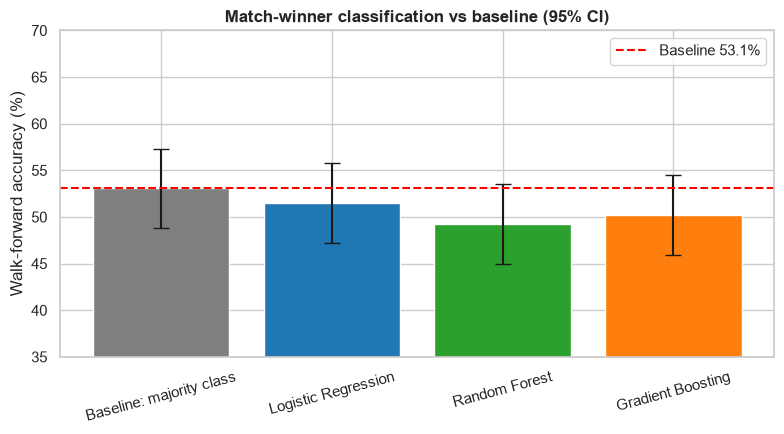

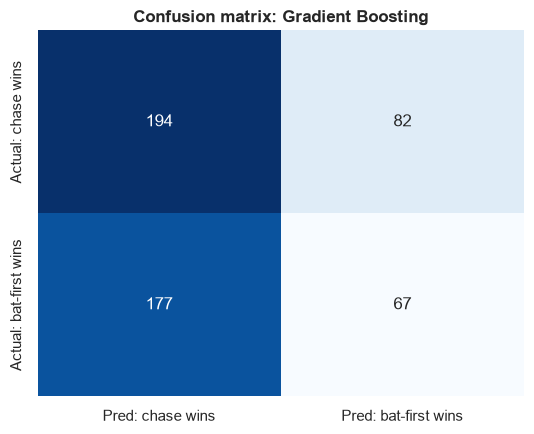

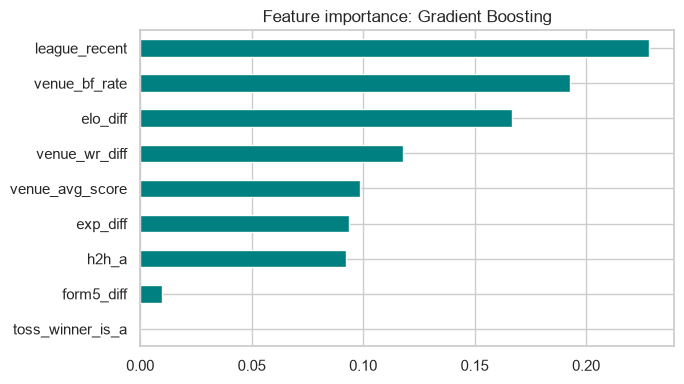


Best model: Gradient Boosting  accuracy 0.502 (95% CI 0.459-0.545) vs baseline 0.531
Reading it: if the baseline accuracy sits inside that interval, the gain is not distinguishable from noise.


In [7]:
# B3. CLASSIFICATION: who wins, predicted after the toss (team batting first vs team chasing)
#     One chronological protocol for every model: walk-forward by season, training only on earlier seasons.
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval for an accuracy of k correct out of n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def walk_forward(df, features, target, models, test_years, kind="clf"):
    """Train on every season before `year`, predict `year`. Returns y_true, row index, {model: predictions}."""
    out = {name: [] for name in models}
    ys, idx = [], []
    for yr in test_years:
        train, test = df[df["year"] < yr], df[df["year"] == yr]
        if len(test) == 0 or len(train) < 50:
            continue
        ys.append(test[target].to_numpy())
        idx.append(test.index.to_numpy())
        for name, mdl in models.items():
            fitted = clone(mdl).fit(train[features], train[target])
            out[name].append(fitted.predict_proba(test[features])[:, 1] if kind == "clf"
                             else fitted.predict(test[features]))
    return np.concatenate(ys), np.concatenate(idx), {n: np.concatenate(v) for n, v in out.items()}


def clf_table(y, probas):
    rows = []
    for name, p in probas.items():
        pred = (p >= 0.5).astype(int)
        lo, hi = wilson_ci(int((pred == y).sum()), len(y))
        rows.append({"Model": name, "Accuracy": accuracy_score(y, pred), "Acc CI low": lo, "Acc CI high": hi,
                     "F1 (bat-first wins)": f1_score(y, pred, zero_division=0),
                     "Macro-F1": f1_score(y, pred, average="macro", zero_division=0),
                     "ROC-AUC": roc_auc_score(y, p),
                     "Log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
                     "Brier": brier_score_loss(y, p)})
    return pd.DataFrame(rows).set_index("Model")


BASELINE = "Baseline: majority class"
clf_models = {
    BASELINE: DummyClassifier(strategy="prior"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=15, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=2,
                                                    subsample=0.8, random_state=42),
}
TEST_YEARS = list(range(2018, int(feat["year"].max()) + 1))

y_clf, idx_clf, proba_clf = walk_forward(feat, CLF_FEATURES, "bat_first_won", clf_models, TEST_YEARS)
clf_results = clf_table(y_clf, proba_clf)

print(f"Walk-forward test seasons {TEST_YEARS[0]}-{TEST_YEARS[-1]}: n = {len(y_clf)} matches "
      f"(batting-first win rate {y_clf.mean():.3f})")
print(clf_results.round(3).to_string())

# ---- accuracy with 95% confidence intervals ----
fig, ax = plt.subplots(figsize=(8, 4.5))
acc = clf_results["Accuracy"] * 100
err = np.vstack([acc - clf_results["Acc CI low"] * 100, clf_results["Acc CI high"] * 100 - acc])
ax.bar(acc.index, acc.values, yerr=err, capsize=6, color=["#7f7f7f", "#1f77b4", "#2ca02c", "#ff7f0e"])
ax.axhline(acc[BASELINE], color="red", ls="--", label=f"Baseline {acc[BASELINE]:.1f}%")
ax.set_ylim(35, 70); ax.set_ylabel("Walk-forward accuracy (%)")
ax.set_title("Match-winner classification vs baseline (95% CI)", fontweight="bold")
plt.xticks(rotation=15); ax.legend(); plt.tight_layout(); plt.show()

# ---- confusion matrix of the best model by ROC-AUC ----
best_clf_name = clf_results.drop(index=BASELINE)["ROC-AUC"].idxmax()
cm_best = confusion_matrix(y_clf, (proba_clf[best_clf_name] >= 0.5).astype(int))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: chase wins", "Pred: bat-first wins"],
            yticklabels=["Actual: chase wins", "Actual: bat-first wins"])
plt.title(f"Confusion matrix: {best_clf_name}", fontweight="bold"); plt.tight_layout(); plt.show()

# ---- final model on all seasons (used by B7) and its importances ----
final_clf = clone(clf_models[best_clf_name]).fit(feat[CLF_FEATURES], feat["bat_first_won"])
if hasattr(final_clf, "feature_importances_"):
    imp = pd.Series(final_clf.feature_importances_, index=CLF_FEATURES).sort_values()
    imp.plot.barh(figsize=(7, 4), color="teal", title=f"Feature importance: {best_clf_name}")
    plt.tight_layout(); plt.show()

lo, hi = clf_results.loc[best_clf_name, ["Acc CI low", "Acc CI high"]]
print(f"\nBest model: {best_clf_name}  accuracy {clf_results.loc[best_clf_name, 'Accuracy']:.3f} "
      f"(95% CI {lo:.3f}-{hi:.3f}) vs baseline {clf_results.loc[BASELINE, 'Accuracy']:.3f}")
print("Reading it: if the baseline accuracy sits inside that interval, the gain is not distinguishable from noise.")

Regression set: 1125 matches | mean total 167.9, std 32.4
Walk-forward test n = 516
                                   MAE    RMSE     R2  Within 20 runs  Score-band accuracy
Model                                                                                     
Baseline: train-set mean        27.941  35.786 -0.136           0.452                0.419
Ridge                           26.298  33.538  0.002           0.453                0.419
Random Forest                   26.617  33.948 -0.022           0.463                0.428
Gradient Boosting               26.401  33.813 -0.014           0.453                0.442
Baseline: venue average so far  26.763  34.748 -0.071           0.465                0.415


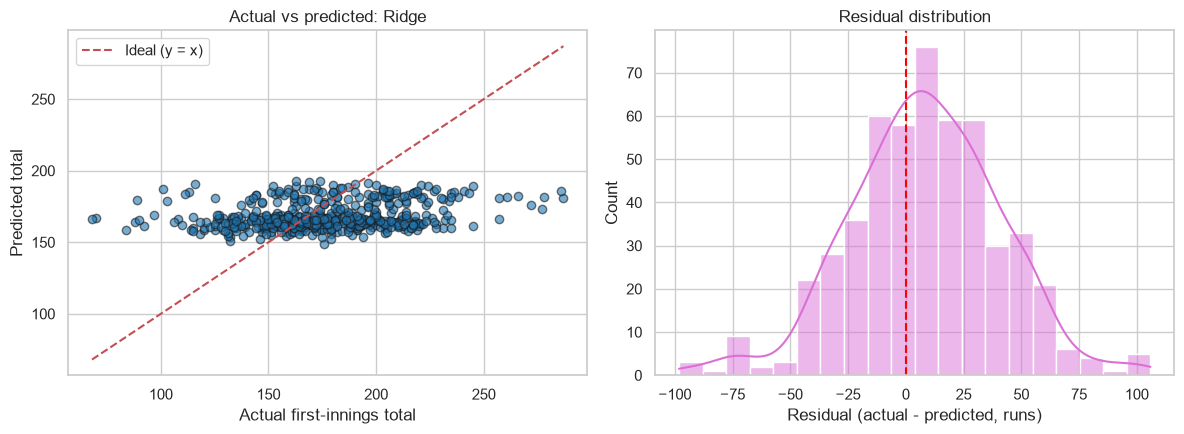


Best: Ridge | MAE 26.3 runs (+0.5 runs better than the venue-average baseline)


In [8]:
# B4. REGRESSION: first-innings total, predicted before the match (real totals, not the first-ball running total)
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg = feat[(feat["scheduled_overs"] == 20) & feat["full1"]].copy()    # complete 20-over first innings only
print(f"Regression set: {len(reg)} matches | mean total {reg['score1'].mean():.1f}, std {reg['score1'].std():.1f}")

BANDS = [-np.inf, 150, 185, np.inf]
BAND_LABELS = ["Low (<150)", "Par (150-185)", "High (>185)"]

reg_models = {
    "Baseline: train-set mean": DummyRegressor(strategy="mean"),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=2,
                                                   subsample=0.8, random_state=42),
}
y_reg, idx_reg, pred_reg = walk_forward(reg, REG_FEATURES, "score1", reg_models, TEST_YEARS, kind="reg")
pred_reg["Baseline: venue average so far"] = reg.loc[idx_reg, "venue_avg_score"].to_numpy()


def reg_table(y, preds):
    rows = []
    for name, p in preds.items():
        band_acc = (pd.cut(pd.Series(y), BANDS, labels=BAND_LABELS).to_numpy()
                    == pd.cut(pd.Series(p), BANDS, labels=BAND_LABELS).to_numpy()).mean()
        rows.append({"Model": name, "MAE": mean_absolute_error(y, p),
                     "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p),
                     "Within 20 runs": float((np.abs(y - p) <= 20).mean()), "Score-band accuracy": band_acc})
    return pd.DataFrame(rows).set_index("Model")


reg_results = reg_table(y_reg, pred_reg)
print(f"Walk-forward test n = {len(y_reg)}")
print(reg_results.round(3).to_string())

best_reg_name = reg_results.drop(index=[n for n in reg_results.index if n.startswith("Baseline")])["MAE"].idxmin()
p_best = pred_reg[best_reg_name]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_reg, p_best, alpha=0.6, edgecolors="k", color="#1f77b4")
lims = [min(y_reg.min(), p_best.min()), max(y_reg.max(), p_best.max())]
axes[0].plot(lims, lims, "r--", label="Ideal (y = x)")
axes[0].set(xlabel="Actual first-innings total", ylabel="Predicted total", title=f"Actual vs predicted: {best_reg_name}")
axes[0].legend()
sns.histplot(y_reg - p_best, bins=20, kde=True, color="orchid", ax=axes[1])
axes[1].axvline(0, color="red", ls="--")
axes[1].set(xlabel="Residual (actual - predicted, runs)", title="Residual distribution")
plt.tight_layout(); plt.show()

gain = reg_results.loc["Baseline: venue average so far", "MAE"] - reg_results.loc[best_reg_name, "MAE"]
print(f"\nBest: {best_reg_name} | MAE {reg_results.loc[best_reg_name, 'MAE']:.1f} runs "
      f"({gain:+.1f} runs better than the venue-average baseline)")

 Checkpoint (overs)                               Model   n  Accuracy  ROC-AUC  Log loss
                  6            Live Logistic Regression 512     0.742    0.835     0.502
                  6              Live Gradient Boosting 512     0.734    0.822     0.532
                  6            Baseline: majority class 512     0.531    0.488     0.692
                  6             Pre-match features only 512     0.518    0.480     0.703
                  6 Heuristic: chase wins if RRR <= CRR 512     0.695    0.773     0.725
                 10            Live Logistic Regression 505     0.772    0.857     0.469
                 10              Live Gradient Boosting 505     0.786    0.847     0.494
                 10            Baseline: majority class 505     0.525    0.486     0.693
                 10             Pre-match features only 505     0.507    0.483     0.703
                 10 Heuristic: chase wins if RRR <= CRR 505     0.699    0.812     0.732
                 15  

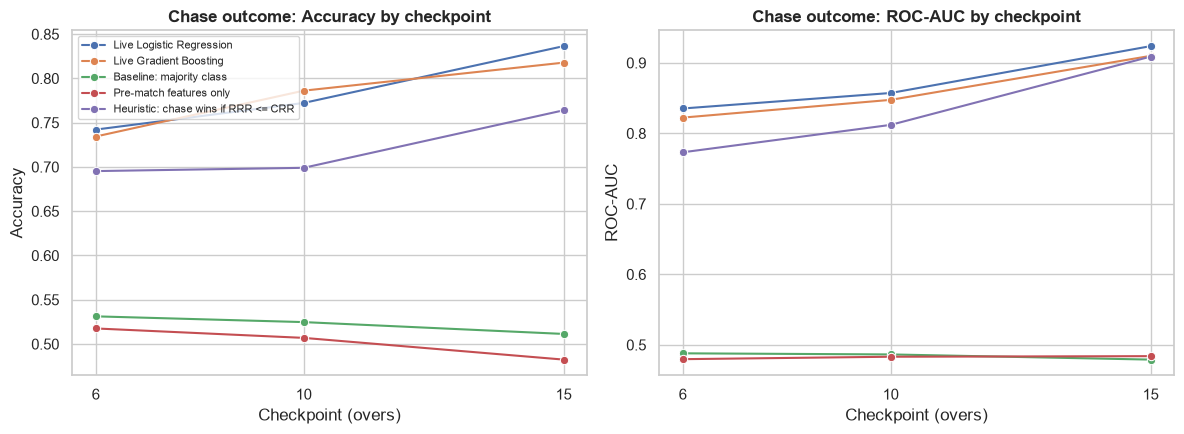


Win-probability timeline | Kolkata Knight Riders 174/8 vs Royal Challengers Bangalore (chasing 175) at Eden Gardens  -> winner: Royal Challengers Bangalore
  after  6 overs: Royal Challengers Bangalore win probability = 95.8%
  after 10 overs: Royal Challengers Bangalore win probability = 95.8%
  after 15 overs: Royal Challengers Bangalore win probability = 97.9%

Projected first-innings total:
 Checkpoint (overs)                                 Model   n   MAE  RMSE
                  6                     Gradient Boosting 516 21.03 26.38
                  6 Baseline: current run rate x 20 overs 516 28.90 36.44
                  6               Baseline: venue average 516 26.76 34.75
                 10                     Gradient Boosting 516 17.22 21.30
                 10 Baseline: current run rate x 20 overs 516 21.97 27.72
                 10               Baseline: venue average 516 26.76 34.75
                 15                     Gradient Boosting 515 11.04 14.17
         

In [9]:
# B5. LIVE-STYLE PREDICTION after 6, 10 and 15 overs (the brief's extension)
#   (a) chase win probability from the 2nd-innings state    (b) projected first-innings total from the 1st-innings state
CHECKPOINTS = (6, 10, 15)


def state_at(k, innings):
    """Score, wickets and legal balls after the first k completed overs of an innings."""
    d = balls[(balls["innings"] == innings) & (balls["over"] < k)]
    return d.groupby("match_id").agg(runs_k=("runs_total", "sum"), wkts_k=("is_wkt", "sum"),
                                     legal_k=("legal", "sum"))


# ---------- (a) chase win probability ----------
LIVE_FEATURES = ["runs_needed", "balls_left", "rrr", "crr", "rrr_minus_crr", "wkts_in_hand",
                 "chase_target", "chase_elo", "venue_avg_score"]
live_sets, live_rows = {}, []
live_models = {
    "Live Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)),
    "Live Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3,
                                                         subsample=0.8, random_state=42),
}
pre_model = {
    "Baseline: majority class": DummyClassifier(strategy="prior"),
    "Pre-match features only": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000)),
}

for k in CHECKPOINTS:
    d = feat.merge(state_at(k, 2), left_on="match_id", right_index=True)
    d = d[(d["scheduled_overs"] == 20) & d["full1"] & (d["legal_k"] == 6 * k) & (d["legal2"] > 6 * k)
          & (d["wkts_k"] < 10) & d["chase_target"].notna() & d["method"].isna()].copy()   # no D/L-revised chases
    d["chase_win"] = 1 - d["bat_first_won"]
    d["runs_needed"] = d["chase_target"] - d["runs_k"]
    d["balls_left"] = 120 - d["legal_k"]
    d["rrr"] = d["runs_needed"] / d["balls_left"] * 6
    d["crr"] = d["runs_k"] / d["legal_k"] * 6
    d["rrr_minus_crr"] = d["rrr"] - d["crr"]
    d["wkts_in_hand"] = 10 - d["wkts_k"]
    d["chase_elo"] = -d["elo_diff"]
    live_sets[k] = d

    y, idx, p = walk_forward(d, LIVE_FEATURES, "chase_win", live_models, TEST_YEARS)
    _, _, p_pre = walk_forward(d, CLF_FEATURES, "chase_win", pre_model, TEST_YEARS)
    p.update(p_pre)
    p["Heuristic: chase wins if RRR <= CRR"] = 1 / (1 + np.exp(-(d.loc[idx, "crr"] - d.loc[idx, "rrr"]).to_numpy()))
    tbl = clf_table(y, p).reset_index()
    tbl.insert(0, "Checkpoint (overs)", k)
    tbl.insert(1, "n", len(y))
    live_rows.append(tbl)

live_results = pd.concat(live_rows, ignore_index=True)
show_cols = ["Checkpoint (overs)", "Model", "n", "Accuracy", "ROC-AUC", "Log loss"]
print(live_results[show_cols].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for metric, ax in zip(["Accuracy", "ROC-AUC"], axes):
    sns.lineplot(data=live_results, x="Checkpoint (overs)", y=metric, hue="Model", marker="o", ax=ax)
    ax.set_xticks(CHECKPOINTS)
    ax.set_title(f"Chase outcome: {metric} by checkpoint", fontweight="bold")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].get_legend().remove()
plt.tight_layout(); plt.show()

# ---------- demo: win-probability timeline for one match from the latest season ----------
last_year = int(feat["year"].max())
fit = {}
for k in CHECKPOINTS:
    d = live_sets[k]
    train = d[d["year"] < last_year]
    fit[k] = clone(live_models["Live Gradient Boosting"]).fit(train[LIVE_FEATURES], train["chase_win"])

common = set.intersection(*[set(live_sets[k].loc[live_sets[k]["year"] == last_year, "match_id"])
                            for k in CHECKPOINTS])
if common:
    mid = sorted(common)[0]
    timeline = {}
    for k in CHECKPOINTS:
        row = live_sets[k][live_sets[k]["match_id"] == mid]
        timeline[k] = float(fit[k].predict_proba(row[LIVE_FEATURES])[0, 1])
    m = matches[matches["match_id"] == mid].iloc[0]
    print(f"\nWin-probability timeline | {m['bat_first']} {m['score1']}/{m['wkts1']} vs {m['chaser']} "
          f"(chasing {m['chase_target']:.0f}) at {m['venue']}  -> winner: {m['winner']}")
    for k, pr in timeline.items():
        print(f"  after {k:>2} overs: {m['chaser']} win probability = {pr:.1%}")

# ---------- (b) projected first-innings total ----------
proj_rows = []
PROJ_FEATURES = ["runs_k", "wkts_k", "crr_k", "venue_avg_score", "exp_score_a", "league_recent"]
for k in CHECKPOINTS:
    d = feat.merge(state_at(k, 1), left_on="match_id", right_index=True)
    d = d[(d["scheduled_overs"] == 20) & d["full1"] & (d["legal_k"] == 6 * k)].copy()
    d["crr_k"] = d["runs_k"] / d["legal_k"] * 6
    gbr = {"Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=2,
                                                          subsample=0.8, random_state=42)}
    y, idx, p = walk_forward(d, PROJ_FEATURES, "score1", gbr, TEST_YEARS, kind="reg")
    p["Baseline: current run rate x 20 overs"] = (d.loc[idx, "crr_k"] * 20).to_numpy()
    p["Baseline: venue average"] = d.loc[idx, "venue_avg_score"].to_numpy()
    for name, pred in p.items():
        proj_rows.append({"Checkpoint (overs)": k, "Model": name, "n": len(y),
                          "MAE": mean_absolute_error(y, pred),
                          "RMSE": float(np.sqrt(mean_squared_error(y, pred)))})
proj_results = pd.DataFrame(proj_rows)
print("\nProjected first-innings total:")
print(proj_results.round(2).to_string(index=False))

 k  inertia  silhouette
 2   58.364       0.419
 3   44.827       0.433
 4   33.587       0.279
 5   24.262       0.262
Highest silhouette at k = 3
                                                       venue  matches  avg_score  score_std  bat_first_win_rate    archetype
                Himachal Pradesh Cricket Association Stadium       14     187.50      34.97                0.64 High scoring
                                       Narendra Modi Stadium       44     180.14      35.04                0.50 High scoring
                                           Brabourne Stadium       27     178.52      32.22                0.52 High scoring
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium       21     177.76      32.43                0.43 High scoring
                                       M Chinnaswamy Stadium       89     177.42      32.78                0.46 High scoring
                                   Barsapara Cricket Stadium        5     174.60      25.72           

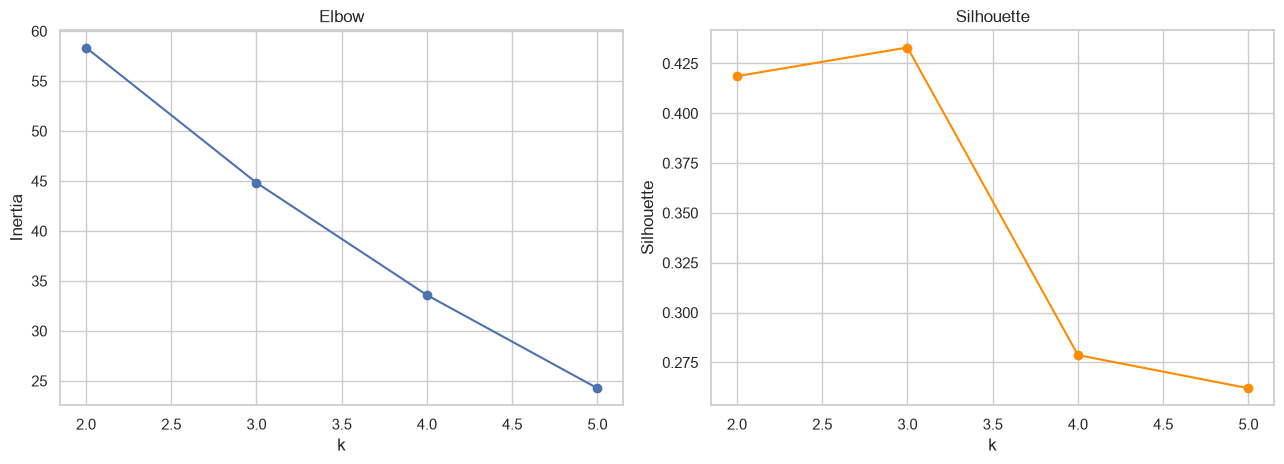

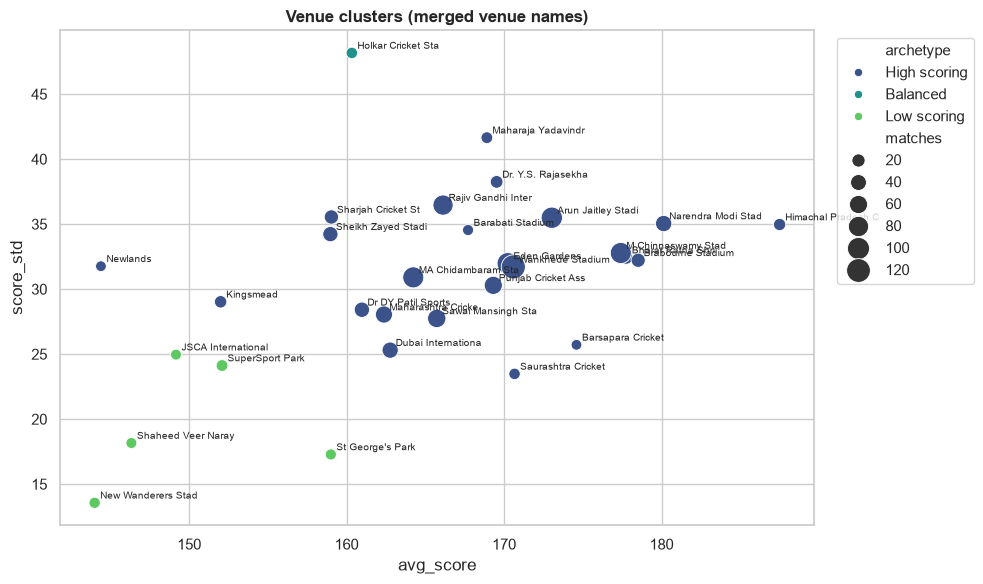

In [10]:
# B6. Pitch / venue clustering: choose k with evidence, using the cleaned (merged) venue names
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

MIN_MATCHES = 5
vs = (matches[matches["full1"]].groupby("venue")
      .agg(avg_score=("score1", "mean"), score_std=("score1", "std"),
           bat_first_win_rate=("bat_first_won", "mean"), matches=("match_id", "count"))
      .reset_index())
vs["score_std"] = vs["score_std"].fillna(0)
vs = vs[vs["matches"] >= MIN_MATCHES].reset_index(drop=True)

CLUSTER_FEATURES = ["avg_score", "score_std", "bat_first_win_rate"]
Xs = StandardScaler().fit_transform(vs[CLUSTER_FEATURES])

diag = []
for k in range(2, min(6, len(vs))):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    diag.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_)})
diag = pd.DataFrame(diag)
print(diag.round(3).to_string(index=False))
print(f"Highest silhouette at k = {int(diag.loc[diag['silhouette'].idxmax(), 'k'])}")

K_FINAL = 3   # keep 3 archetypes for continuity with your earlier cell; set to the best-silhouette k if you prefer
km = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10).fit(Xs)
vs["cluster"] = km.labels_
order = vs.groupby("cluster")["avg_score"].mean().sort_values().index
names = ["Low scoring"] + ["Balanced"] * (K_FINAL - 2) + ["High scoring"]
vs["archetype"] = vs["cluster"].map(dict(zip(order, names if K_FINAL > 2 else ["Low scoring", "High scoring"])))
venue_clusters = vs.sort_values("avg_score", ascending=False)
print(venue_clusters[["venue", "matches", "avg_score", "score_std", "bat_first_win_rate", "archetype"]]
      .round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(diag["k"], diag["inertia"], "o-"); axes[0].set(xlabel="k", ylabel="Inertia", title="Elbow")
axes[1].plot(diag["k"], diag["silhouette"], "o-", color="darkorange"); axes[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=vs, x="avg_score", y="score_std", hue="archetype", size="matches", sizes=(60, 300),
                palette="viridis")
for r in vs.itertuples():
    plt.annotate(r.venue[:18], (r.avg_score, r.score_std), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.title("Venue clusters (merged venue names)", fontweight="bold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

In [11]:
# B7. Pre-match prediction that actually uses BOTH teams (the earlier version ignored team1/team2
#     and reported the toss winner's probability as team1's)
def predict_pre_match(team_bat_first, team_chasing, venue, toss_winner=None, verbose=True):
    a, b = normalise_team(team_bat_first), normalise_team(team_chasing)
    v = normalise_venue(venue)
    tw = normalise_team(toss_winner) if toss_winner else a
    if a not in state.elo or b not in state.elo:
        raise ValueError(f"Unknown team: {[t for t in (a, b) if t not in state.elo]}")
    if v not in state.venue_scores:
        print(f"Note: no full-innings history at '{v}'; venue features fall back to league averages.")
    X = pd.DataFrame([state.features(a, b, v, tw)])[CLF_FEATURES]
    p_a = float(final_clf.predict_proba(X)[0, 1])
    winner = a if p_a >= 0.5 else b
    if verbose:
        print("=" * 56)
        print(f" {a} (bat first) vs {b} (chase)   |   {v}")
        print(f" Toss won by: {tw}")
        print("-" * 56)
        print(f" {a:<30} {p_a:6.1%}")
        print(f" {b:<30} {1 - p_a:6.1%}")
        print(f" Predicted winner: {winner}   (model: {best_clf_name})")
        print("=" * 56)
    return {"bat_first": a, "chasing": b, "p_bat_first_wins": p_a, "predicted_winner": winner}


_ = predict_pre_match("Mumbai Indians", "Chennai Super Kings", "Wankhede Stadium", toss_winner="Mumbai Indians")
_ = predict_pre_match("Chennai Super Kings", "Mumbai Indians", "MA Chidambaram Stadium, Chepauk", toss_winner="Chennai Super Kings")

 Mumbai Indians (bat first) vs Chennai Super Kings (chase)   |   Wankhede Stadium
 Toss won by: Mumbai Indians
--------------------------------------------------------
 Mumbai Indians                  46.9%
 Chennai Super Kings             53.1%
 Predicted winner: Chennai Super Kings   (model: Gradient Boosting)
 Chennai Super Kings (bat first) vs Mumbai Indians (chase)   |   MA Chidambaram Stadium
 Toss won by: Chennai Super Kings
--------------------------------------------------------
 Chennai Super Kings             41.8%
 Mumbai Indians                  58.2%
 Predicted winner: Mumbai Indians   (model: Gradient Boosting)


Explained 70 matches from 2025 (model trained on earlier seasons only)


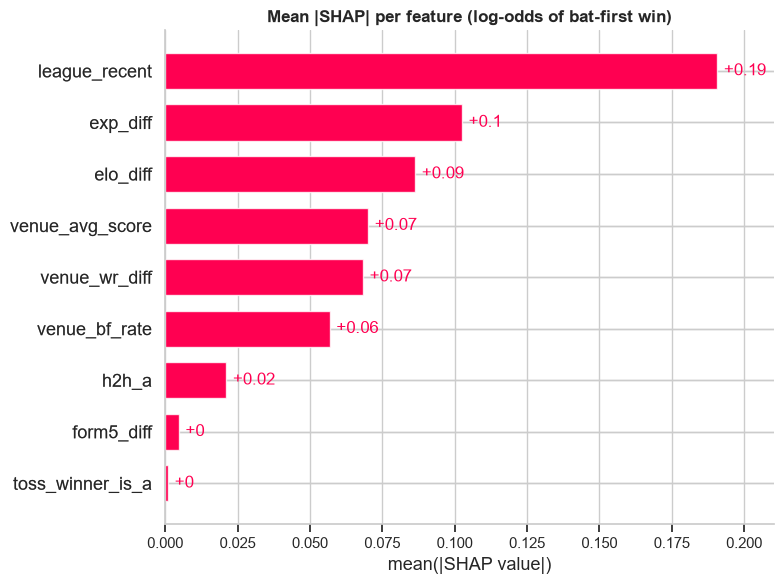

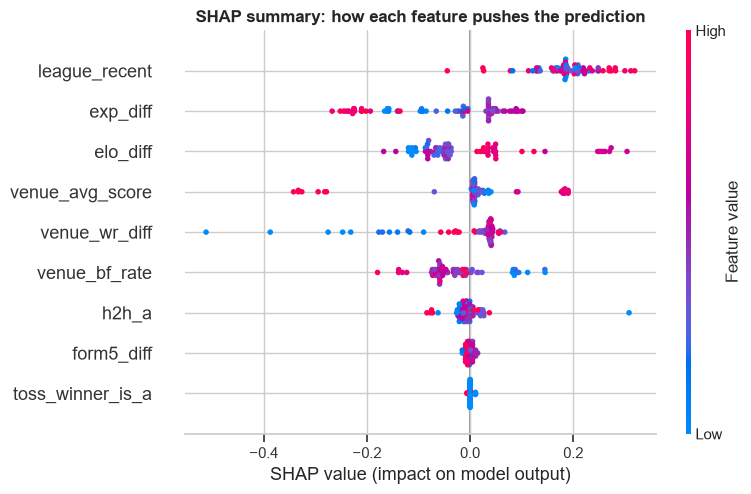

Kolkata Knight Riders (bat first) vs Royal Challengers Bangalore at Eden Gardens | actual winner: chasing team


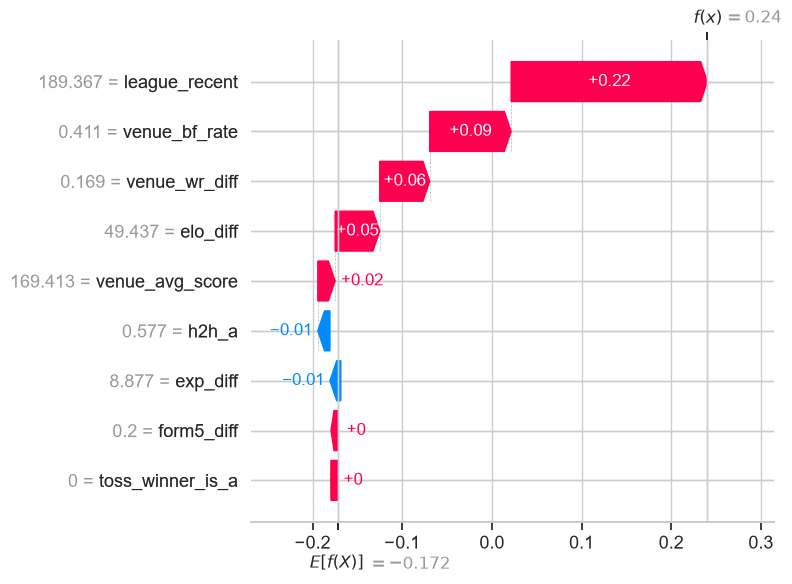

In [13]:
# B8. EXPLAINABLE AI: SHAP for the new match-winner model (the pre-match features, not Model 1)
#     Run `!pip install shap` once if the import fails.
import shap
from sklearn.base import clone

# A tree model is used for the explanation so TreeExplainer applies whichever model won in B3.
last_year = int(feat["year"].max())
shap_train = feat[feat["year"] < last_year]
shap_test = feat[feat["year"] == last_year].reset_index(drop=True)

shap_model = clone(clf_models["Gradient Boosting"]).fit(shap_train[CLF_FEATURES], shap_train["bat_first_won"])
explainer = shap.TreeExplainer(shap_model)
sv = explainer(shap_test[CLF_FEATURES])          # values are in log-odds of "batting-first team wins"
print(f"Explained {len(shap_test)} matches from {last_year} (model trained on earlier seasons only)")

# 1) global importance: mean |SHAP|
plt.figure()
shap.plots.bar(sv, show=False)
plt.title("Mean |SHAP| per feature (log-odds of bat-first win)", fontweight="bold")
plt.tight_layout(); plt.show()

# 2) direction of effect: beeswarm
plt.figure()
shap.plots.beeswarm(sv, show=False)
plt.title("SHAP summary: how each feature pushes the prediction", fontweight="bold")
plt.tight_layout(); plt.show()

# 3) one match explained: waterfall
match_no = 0   # change to explain a different match from shap_test
row = shap_test.loc[match_no]
print(f"{row['bat_first']} (bat first) vs {row['chaser']} at {row['venue']} | actual winner: "
      f"{'bat-first team' if row['bat_first_won'] == 1 else 'chasing team'}")
plt.figure()
shap.plots.waterfall(sv[match_no], show=False)
plt.tight_layout(); plt.show()

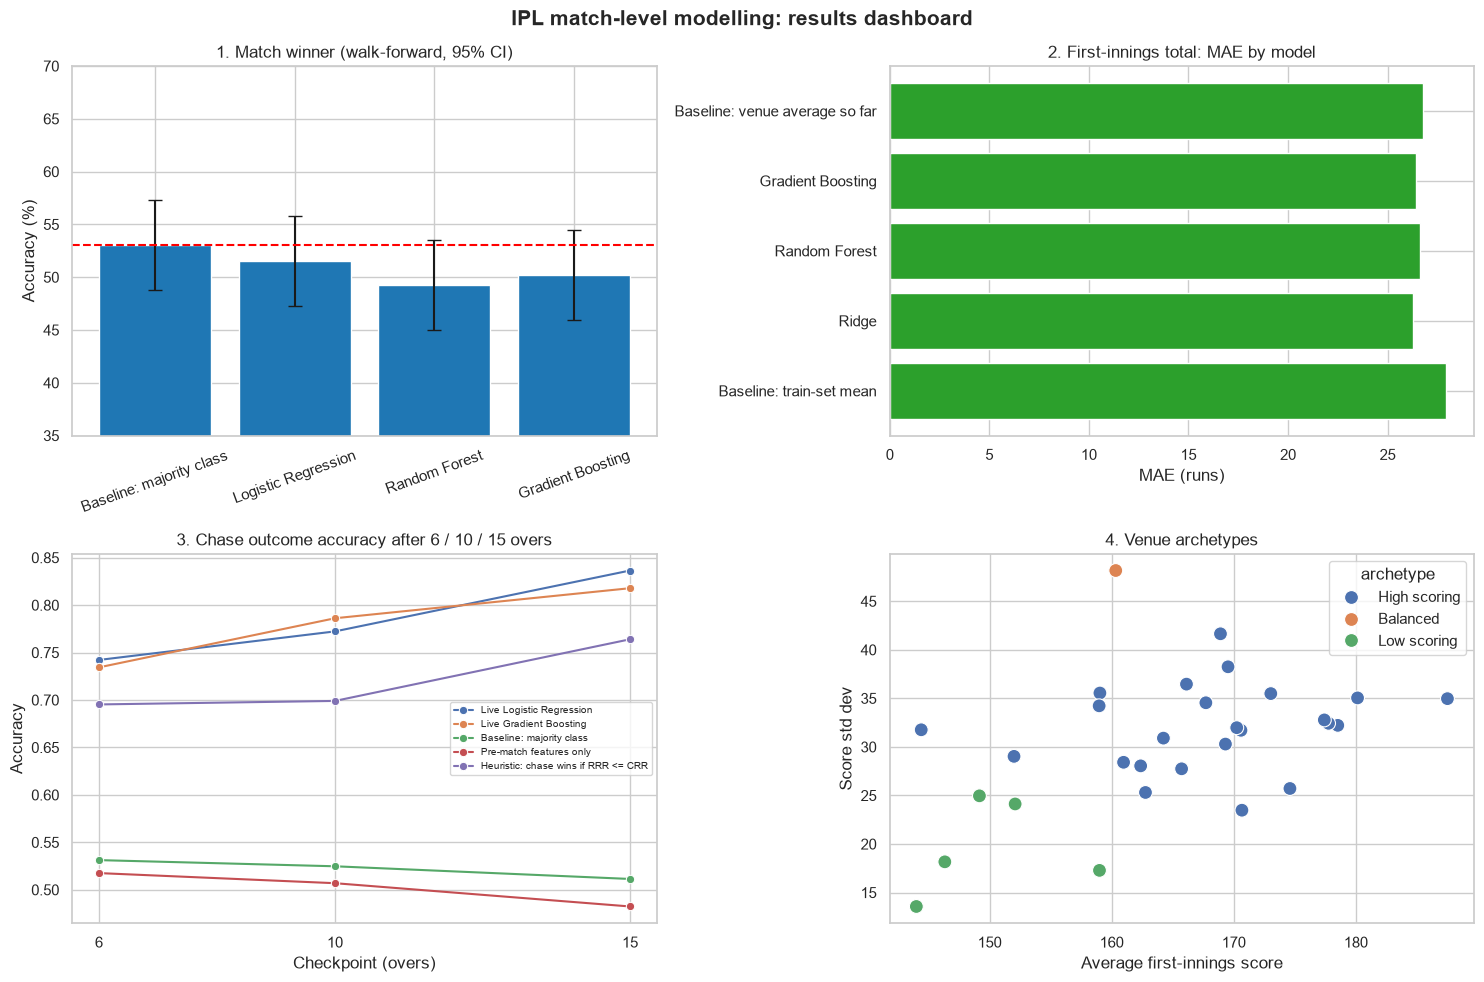

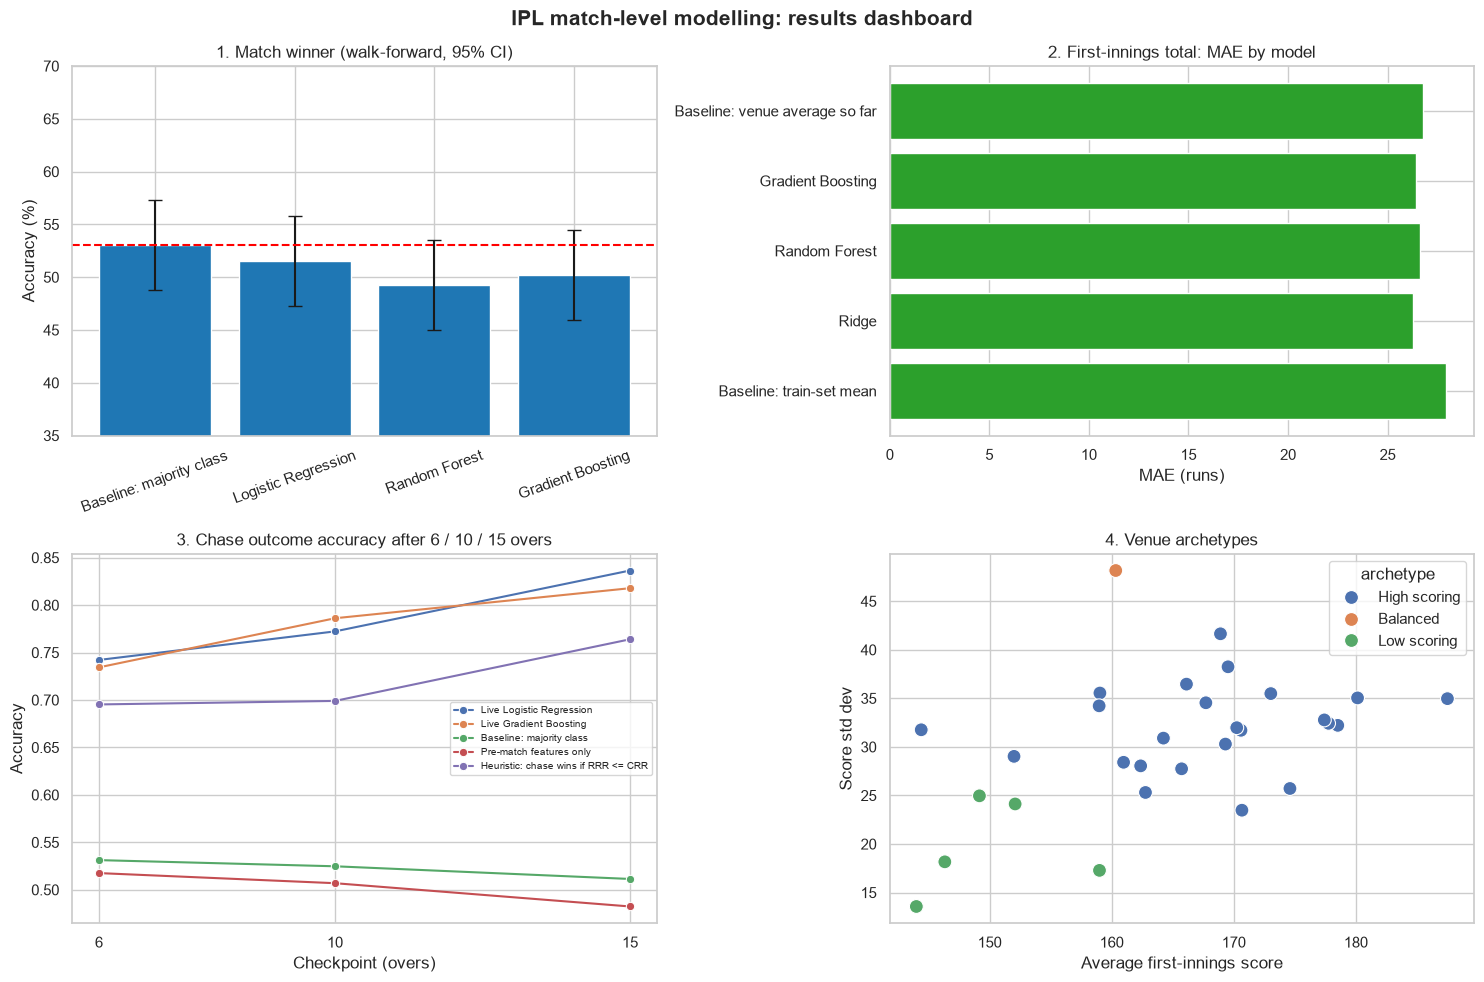

In [22]:
# B9. Dashboard-style summary 
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

clf_results.to_csv(RESULTS / "classification_results.csv")
reg_results.to_csv(RESULTS / "regression_results.csv")
live_results.to_csv(RESULTS / "live_chase_results.csv", index=False)
proj_results.to_csv(RESULTS / "live_projection_results.csv", index=False)
venue_clusters.to_csv(RESULTS / "venue_clusters.csv", index=False)
feat.to_csv(RESULTS / "match_features.csv", index=False)

# ---- one-page dashboard ----
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

acc = clf_results["Accuracy"] * 100
err = np.vstack([acc - clf_results["Acc CI low"] * 100, clf_results["Acc CI high"] * 100 - acc])
axes[0, 0].bar(acc.index, acc.values, yerr=err, capsize=5, color="#1f77b4")
axes[0, 0].axhline(acc[BASELINE], color="red", ls="--")
axes[0, 0].set(ylim=(35, 70), ylabel="Accuracy (%)", title="1. Match winner (walk-forward, 95% CI)")
axes[0, 0].tick_params(axis="x", rotation=20)

mae = reg_results["MAE"]
axes[0, 1].barh(mae.index, mae.values, color="#2ca02c")
axes[0, 1].set(xlabel="MAE (runs)", title="2. First-innings total: MAE by model")

sns.lineplot(data=live_results, x="Checkpoint (overs)", y="Accuracy", hue="Model", marker="o", ax=axes[1, 0])
axes[1, 0].set_xticks(CHECKPOINTS); axes[1, 0].legend(fontsize=7)
axes[1, 0].set_title("3. Chase outcome accuracy after 6 / 10 / 15 overs")

sns.scatterplot(data=venue_clusters, x="avg_score", y="score_std", hue="archetype", s=100, ax=axes[1, 1])
axes[1, 1].set(xlabel="Average first-innings score", ylabel="Score std dev", title="4. Venue archetypes")
plt.suptitle("IPL match-level modelling: results dashboard", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.savefig(RESULTS / "dashboard.png", dpi=150); plt.show()

